# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [2]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    plot_raw,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [3]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 9.5e-9    # top-gate hBN thickness, m    # <-- validate
t_bg = 11e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run** (`plot_raw(g)`); **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [ ]:
g = run(<id>)                 # open + re-form via helpers
plot_raw(g)                   # raw view FIRST — rails/clipping, dead channels, streaks live here

In [ ]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Run 0–3 — Gate C: gate-current sanity check, contact liveness, CNP reconnaissance

`recipe: device-init/gate-current-sanity-check.md`. Four legs, each gate driven
0 → each committed card limit with the other parked at 0. B = 0, V_si = 0,
T = 1.175 K, I_bias = 49.2 nA, τ = 0.1 s / 24 dB/oct, dwell 0.70 s.
151/151 points each, none interrupted.

Raw first, per the analysis discipline above — every lock-in channel gain-divided
on the run's own axes, before any reduction.


run 0
  type:    1D sweep
  recipe:  gate-current-sanity-check
  tags:    gate: k_tg, leg: 0 -> +1 V (committed card limit), k_bg parked at 0 V; V_si = 0 V; B = 0 T, I_bias = 4.9233e-08 A, drive 5.0 V @ 13.777 Hz, sr1 tau=0.1 s slope=24 dB/oct, dwell=0.70 s, Gate C liveness on the provided hardwired configuration: source T_0, drain B_3 (sr0), Rxx B_1-B_2 (sr1); sr2/sr3 n.c.
  rows:    151 of 151 (complete)
  swept:   k_2400_tg_volt 0 → 1 (monotonic)


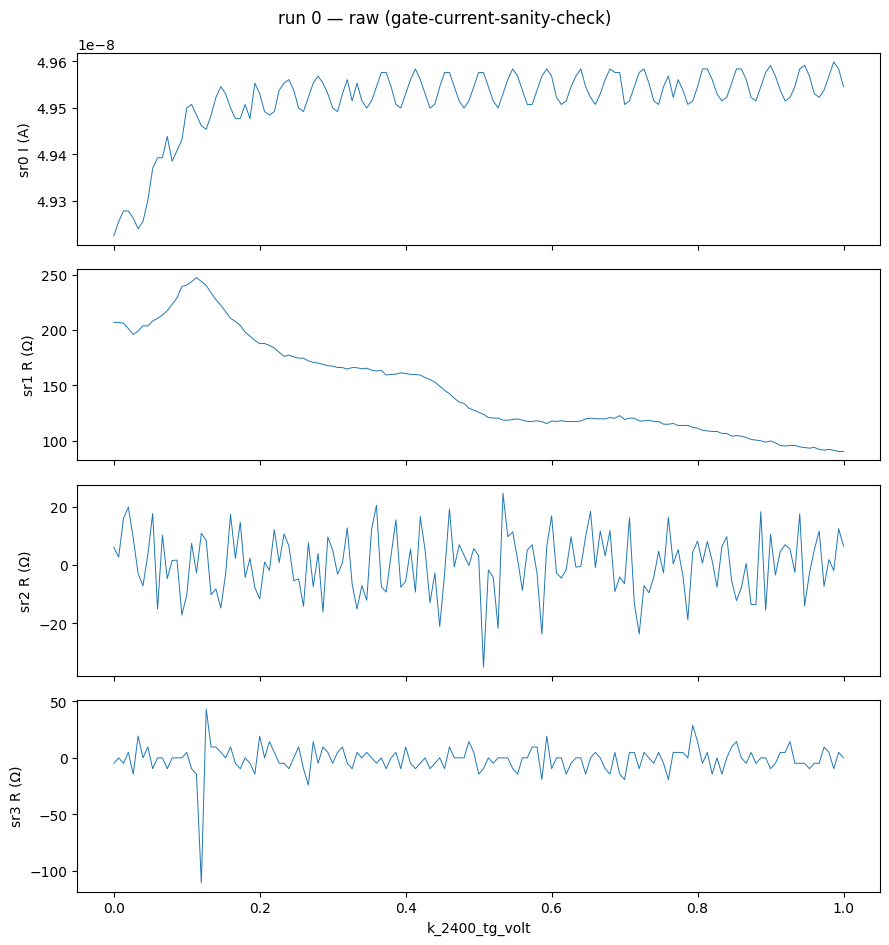

run 1
  type:    1D sweep
  recipe:  gate-current-sanity-check
  tags:    gate: k_tg, leg: 0 -> -0.3 V (committed card limit), k_bg parked at 0 V; V_si = 0 V; B = 0 T, I_bias = 4.9233e-08 A, drive 5.0 V @ 13.777 Hz, sr1 tau=0.1 s slope=24 dB/oct, dwell=0.70 s, Gate C liveness on the provided hardwired configuration: source T_0, drain B_3 (sr0), Rxx B_1-B_2 (sr1); sr2/sr3 n.c.
  rows:    151 of 151 (complete)
  swept:   k_2400_tg_volt 0 → -0.3 (monotonic)


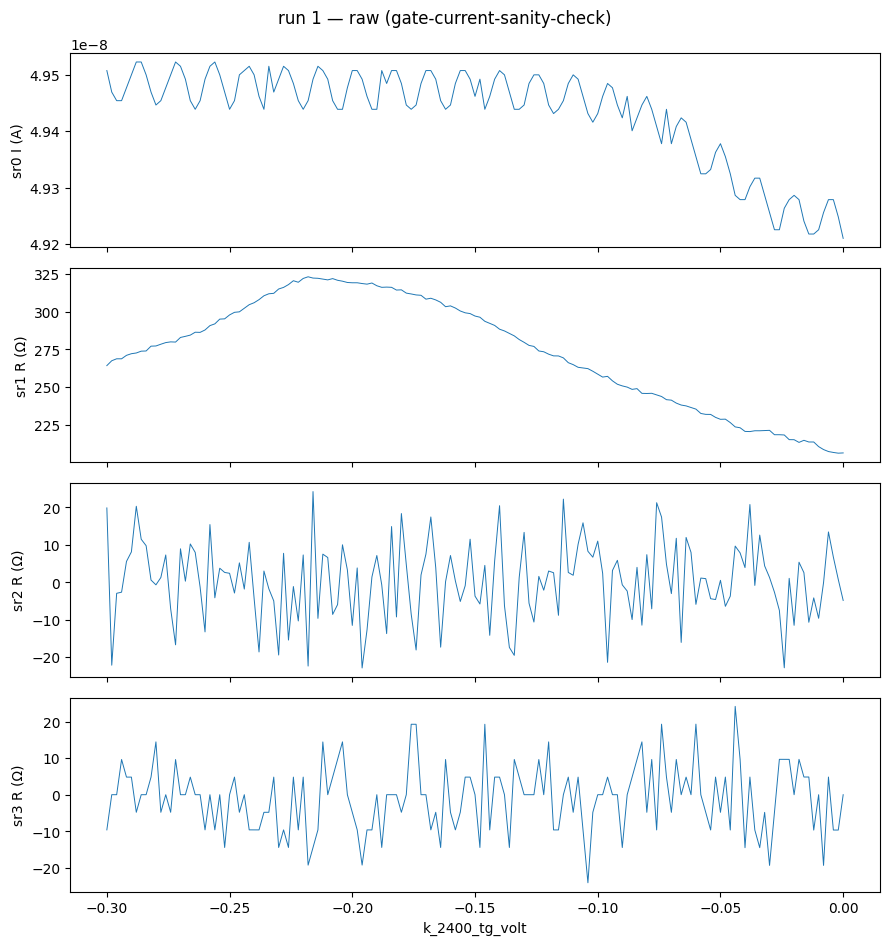

run 2
  type:    1D sweep
  recipe:  gate-current-sanity-check
  tags:    gate: k_bg, leg: 0 -> +2 V (committed card limit), k_tg parked at 0 V; V_si = 0 V; B = 0 T, I_bias = 4.9233e-08 A, drive 5.0 V @ 13.777 Hz, sr1 tau=0.1 s slope=24 dB/oct, dwell=0.70 s, Gate C liveness on the provided hardwired configuration: source T_0, drain B_3 (sr0), Rxx B_1-B_2 (sr1); sr2/sr3 n.c.
  rows:    151 of 151 (complete)
  swept:   k_2400_bg_volt 0 → 2 (monotonic)


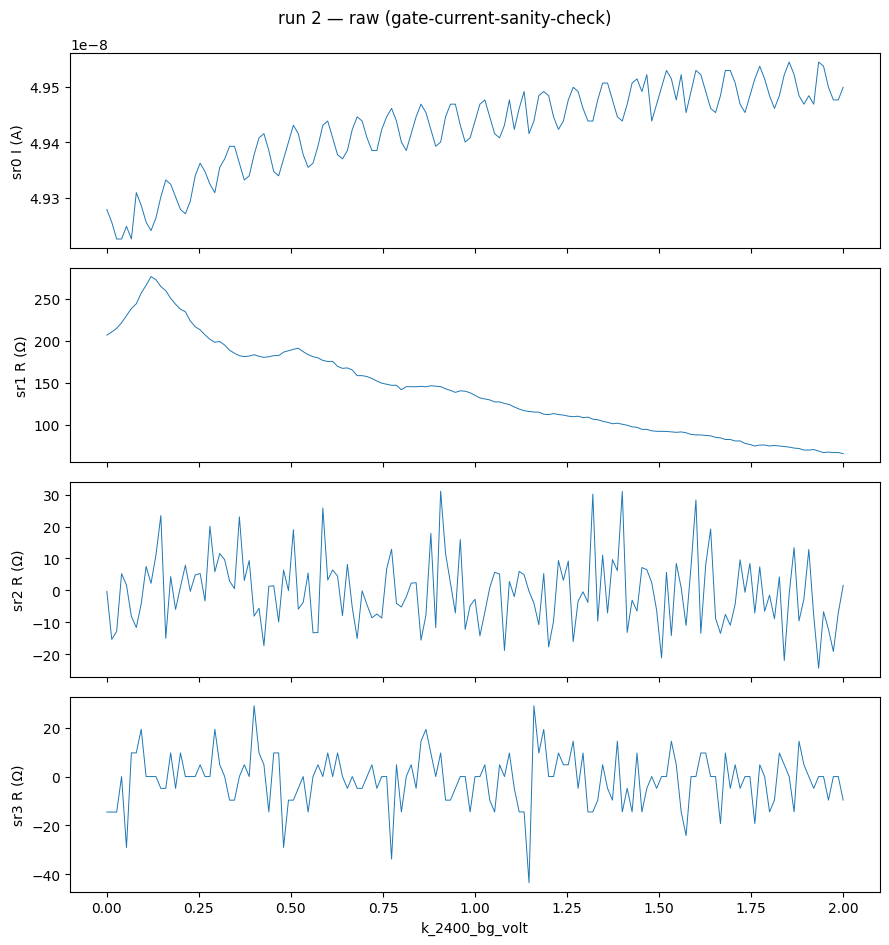

run 3
  type:    1D sweep
  recipe:  gate-current-sanity-check
  tags:    gate: k_bg, leg: 0 -> -1.3 V (committed card limit), k_tg parked at 0 V; V_si = 0 V; B = 0 T, I_bias = 4.9233e-08 A, drive 5.0 V @ 13.777 Hz, sr1 tau=0.1 s slope=24 dB/oct, dwell=0.70 s, Gate C liveness on the provided hardwired configuration: source T_0, drain B_3 (sr0), Rxx B_1-B_2 (sr1); sr2/sr3 n.c.
  rows:    151 of 151 (complete)
  swept:   k_2400_bg_volt 0 → -1.3 (monotonic)


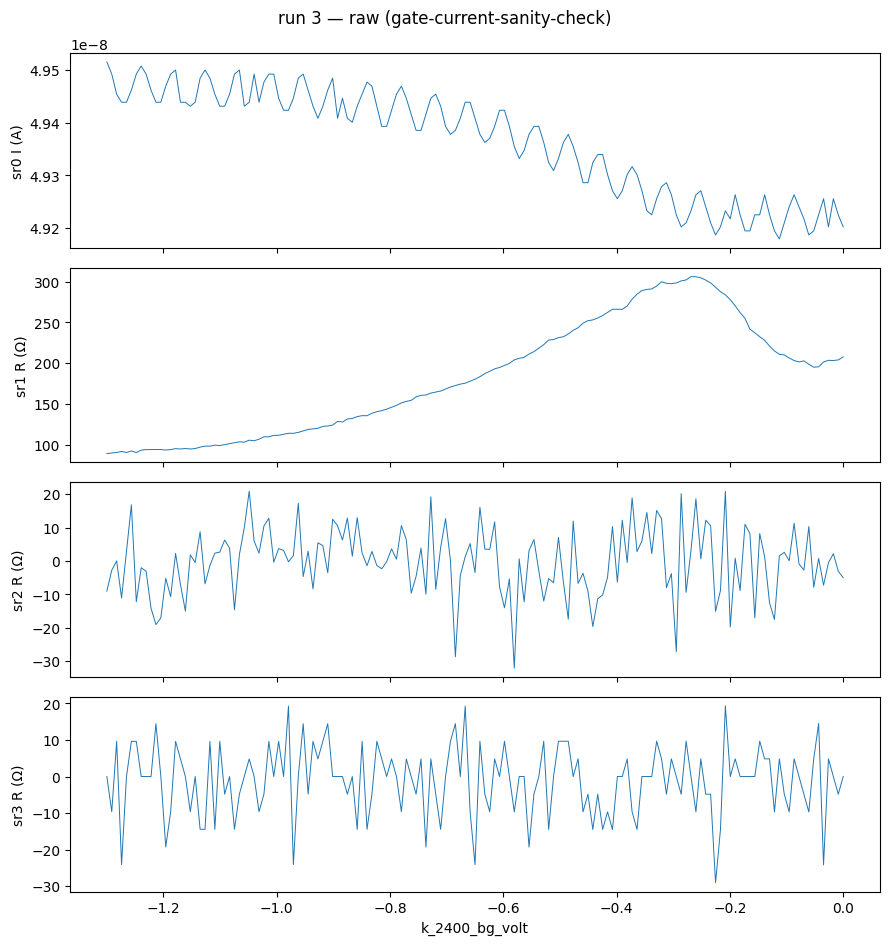

In [4]:
# Gate C — raw first. Four gate-current-sanity-check legs, every lock-in
# channel gain-divided on the run's own axes. Rails, dead channels, and drift
# are visible here and hidden by any derived view.
for rid in (0, 1, 2, 3):
    r = run(rid)
    print(summarize_run(r))
    plot_raw(r)
    plt.show()


<>:44: SyntaxWarning: invalid escape sequence '\O'
<>:44: SyntaxWarning: invalid escape sequence '\O'
C:\Users\DGG\AppData\Local\Temp\ipykernel_17436\1794833639.py:44: SyntaxWarning: invalid escape sequence '\O'
  a.annotate(f"{v:+.3f} V\n{rr:.0f} $\Omega$", (v, rr), textcoords="offset points",


run 0  k_2400_tg_volt  R_xx 90.2-247.5 ohm   I_tg excess 96 pA   I_bg excess 11 pA
    RIDGE k_2400_tg_volt = +0.1121 V   R = 241.5 ohm   prominence 39.7 ohm
run 1  k_2400_tg_volt  R_xx 206.4-323.0 ohm   I_tg excess 25 pA   I_bg excess 11 pA
    RIDGE k_2400_tg_volt = -0.2152 V   R = 321.8 ohm   prominence 54.9 ohm
run 2  k_2400_bg_volt  R_xx 65.6-276.6 ohm   I_tg excess 14 pA   I_bg excess 18 pA
    RIDGE k_2400_bg_volt = +0.1284 V   R = 264.8 ohm   prominence 52.7 ohm
run 3  k_2400_bg_volt  R_xx 89.1-306.3 ohm   I_tg excess 21 pA   I_bg excess 13 pA
    RIDGE k_2400_bg_volt = -0.2642 V   R = 303.3 ohm   prominence 104.1 ohm


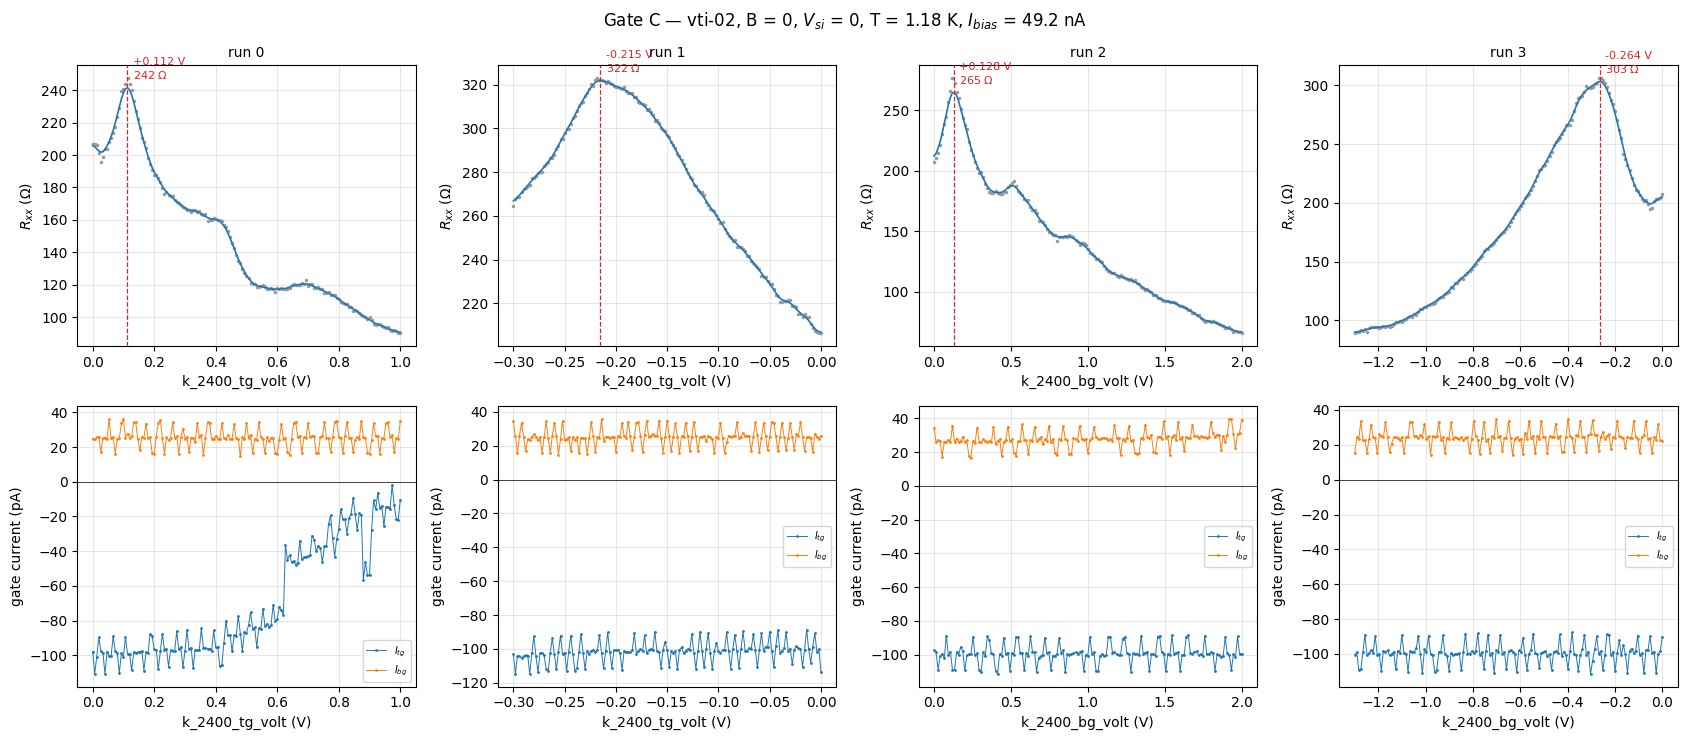


TG-axis ridges (V_bg=0): ['-0.2152', '+0.1121']
BG-axis ridges (V_tg=0): ['-0.2642', '+0.1284']
  ridge A: (V_tg=-0.2152, V_bg=-0.2642)  ->  c_bg/c_tg = 0.8144
  ridge B: (V_tg=+0.1121, V_bg=+0.1284)  ->  c_bg/c_tg = 0.8730
  geometry prior c_bg/c_tg = 0.8636


In [5]:
# Gate C — the reduced read: ridge positions per leg, leakage, cap ratio.
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

def ridges(V, R, smooth=2.0, prom_frac=0.03):
    """Peaks in R(V) on a smoothed trace, parabolic-refined. Raw argmax is not
    good enough here: it moved ridge B's implied cap ratio from 0.958 to 0.873."""
    o = np.argsort(V); Vs, Rs = V[o], R[o]
    Rsm = gaussian_filter1d(Rs, smooth)
    idx, props = find_peaks(Rsm, prominence=prom_frac * np.ptp(Rsm))
    out = []
    for i, p in zip(idx, props["prominences"]):
        if 0 < i < len(Vs) - 1:
            y0, y1, y2 = Rsm[i-1], Rsm[i], Rsm[i+1]
            d = y0 - 2*y1 + y2
            shift = 0.5*(y0 - y2)/d if d else 0.0
            vpk = Vs[i] + shift*np.median(np.diff(Vs))
        else:
            vpk = Vs[i]
        out.append((vpk, Rsm[i], p))
    return Vs, Rsm, out

legs, peaks = {}, {}
fig, ax = plt.subplots(2, 4, figsize=(17, 7.5))
for k, rid in enumerate((0, 1, 2, 3)):
    r = run(rid)
    xcol = max([c for c in r.cols if c.endswith("_volt")], key=lambda c: np.ptp(r.col(c)))
    V = r.col(xcol)
    I = r.col("sr0_X") / r.meta["measurement_config"]["sr0_gain"]
    R = r.col("sr1_X") / I
    itg, ibg = r.col("k_2400_tg_curr"), r.col("k_2400_bg_curr")
    Vs, Rsm, pk = ridges(V, R)
    legs[rid], peaks[rid] = (xcol, V, R, itg, ibg), pk
    print(f"run {rid}  {xcol}  R_xx {R.min():.1f}-{R.max():.1f} ohm   "
          f"I_tg excess {np.abs(itg-itg[0]).max()*1e12:.0f} pA   "
          f"I_bg excess {np.abs(ibg-ibg[0]).max()*1e12:.0f} pA")
    for v, rr, p in pk:
        print(f"    RIDGE {xcol} = {v:+.4f} V   R = {rr:.1f} ohm   prominence {p:.1f} ohm")

    a = ax[0][k]
    a.plot(V, R, ".", ms=3, color="0.6"); a.plot(Vs, Rsm, "-", lw=1.2)
    for v, rr, p in pk:
        a.axvline(v, color="C3", ls="--", lw=0.9)
        a.annotate(f"{v:+.3f} V\n{rr:.0f} $\Omega$", (v, rr), textcoords="offset points",
                   xytext=(4, 6), fontsize=8, color="C3")
    a.set_xlabel(f"{xcol} (V)"); a.set_ylabel(r"$R_{xx}$ ($\Omega$)")
    a.set_title(f"run {rid}", fontsize=10); a.grid(alpha=0.3)

    a = ax[1][k]
    a.plot(V, itg*1e12, ".-", ms=2, lw=0.7, label="$I_{tg}$")
    a.plot(V, ibg*1e12, ".-", ms=2, lw=0.7, label="$I_{bg}$")
    a.axhline(0, color="k", lw=0.5)
    a.set_xlabel(f"{xcol} (V)"); a.set_ylabel("gate current (pA)")
    a.grid(alpha=0.3); a.legend(fontsize=7)
fig.suptitle("Gate C — vti-02, B = 0, $V_{si}$ = 0, T = 1.18 K, $I_{bias}$ = 49.2 nA")
fig.tight_layout(); plt.show()

# two-point cap ratio: a CNP line through (Vtg_i, 0) and (0, Vbg_i) has
# c_bg/c_tg = Vtg_i / Vbg_i
tg = sorted(v for v, _, _ in peaks[0] + peaks[1])
bg = sorted(v for v, _, _ in peaks[2] + peaks[3])
print(f"\nTG-axis ridges (V_bg=0): {['%+.4f' % v for v in tg]}")
print(f"BG-axis ridges (V_tg=0): {['%+.4f' % v for v in bg]}")
for vt, vb, name in zip(tg, bg, "AB"):
    print(f"  ridge {name}: (V_tg={vt:+.4f}, V_bg={vb:+.4f})  ->  c_bg/c_tg = {vt/vb:.4f}")
print(f"  geometry prior c_bg/c_tg = {t_bg/t_tg if False else 9.5/11:.4f}")


**Read.**

*Gates.* Safe on both polarities of both gates. BG is flat at its +25 pA readback
offset everywhere, on both legs, and shows no cross-gate tracking. **TG is not
flat**: run 0 holds −97 pA out to V_tg ≈ 0.62 V, then turns up sharply and
reaches −10 pA at +1.0 V — **+88 pA of voltage-dependent gate current with a
distinct onset**, which capacitive charging does not do. It appears only on
TG-positive (run 1, TG-negative, is flat at −100 pA). It sits below the recipe's
1 nA abort and just under its 100 pA surface-it line, so this is a flag, not a
stop; `gate-leakage-survey` is blocklisted this session, so it is recorded rather
than characterised. Consequence for design: the committed +1.0 V is used anyway,
because capping at 0.6 V would drop the reachable D = 0 electron density from
≈3.3 to ≈1.9×10¹² cm⁻² — below where the ABAB and ABCA templates separate.

*Contacts.* The provided hardwired configuration is fully live: sr0 (drain
current on B_3) tracks at 49.2 nA with 0.7% spread across every leg, sr1
(B_1−B_2) gives a clean resistive four-terminal signal at θ ≈ −3°, and sr2/sr3
sit at the n.c. pickup floor. No dead provided contact — nothing to hand back
for rewiring.

*The science.* **Two resistance ridges along each gate axis, not one**, with a
shallow minimum between them near the origin:

| ridge | V_tg at V_bg = 0 | V_bg at V_tg = 0 | implied c_bg/c_tg |
|---|---|---|---|
| A | −0.2152 V (322 Ω) | −0.2642 V (303 Ω) | **0.814** |
| B | +0.1121 V (242 Ω) | +0.1284 V (265 Ω) | **0.873** |
| geometry prior | | | 0.864 |

Both ridges return a lever-arm ratio consistent with the geometry prior and with
each other to ~6–7%, i.e. **the two ridges are parallel** — two CNP lines rather
than one CNP plus a band feature. The leading interpretation is **two regions of
differing intrinsic doping in series along the B_1−B_2 span**, offset by roughly
0.6×10¹² cm⁻².

Method note, because it changed the answer: raw per-point argmax gave 0.830 and
0.958 for the two ridges and I read that as *non*-parallel. Gaussian smoothing
plus parabolic refinement of the peak moved ridge B from 0.958 to 0.873 and
reversed the conclusion. On peaks this broad and this close to the origin, the
ratio is far too sensitive to peak-picking for a two-point estimate to carry a
claim — which is the argument for the gate map, where the slope is fitted across
many rows with residuals.

*Why this is a problem and not a result.* If B_1−B_2 spans two domains at
different densities, then at any gate setting each region carries its own n and
contributes its own SdH frequency. **Two tones arising from two doping domains
would masquerade as the two Fermi surfaces that are exactly the ABAB signature
this campaign is trying to detect.** This is a distinct confound from the mixed
*stacking* domains the investigation discusses — those share a common gated
density and check against a common F_L; these do not. It has to be resolved
before any FS count is meaningful.

*D-dependence, noted not concluded.* All four peak heights are at finite D. Ridge
A sits at ~2× ridge B's |D| and reads higher (322/303 Ω vs 242/265 Ω), and both
ridges read higher at D < 0 than at D > 0. So the height difference between
ridges may be entirely a |D| effect rather than intrinsic. Each ridge's
resistance *at D = 0* — the number that bears on stacking, and then only as
consistent-with — comes from the gate map.

**Next:** the 0 T gate map over the full committed TG window × V_bg ∈ [−1.3, +1.3],
to fit both ridge slopes with residuals, produce the data-calibrated c_bg/c_tg,
and read each ridge at D = 0.


## Run 4 — first 0 T gate map (V_tg × V_bg), the CNP-line calibration substrate

`recipe: measurements/gatemap.md`, feeding `device-init/cnp-and-dline-calibration.md`.
V_tg fast [−0.3, +1.0] × 101 (13 mV) at V_bg ∈ [−1.3, +1.3] × 37 (72 mV),
3737 points, B = 0, V_si = 0, T = 1.175 K, I_bias = 49.2 nA, dwell 0.70 s.
Complete, not interrupted, 52 min, no railing (max sr1 load 0.34).

Excluded by design: V_bg ∈ (1.3, 2.0], where Gate C run 2 showed R falling
smoothly with no new ridge, and which is high-D electron side, off the D ≈ 0
operating point the investigation requires.


run 4
  type:    2D sweep
  recipe:  gatemap
  tags:    first 0 T gate map, B = 0 T, V_si = 0 V, base T, V_tg fast -0.3..+1 V x101; V_bg slow -1.3..+1.3 V x37, I_bias = 4.9233e-08 A, drive 5.0 V @ 13.777 Hz, sr1 tau=0.1 s slope=24 dB/oct, fast_delay=0.70 s (measured 7*tau settling floor), substrate for device-init/cnp-and-dline-calibration, contacts hardwired: source T_0, drain B_3 (sr0), Rxx B_1-B_2 (sr1); sr2/sr3 n.c., NOTE: TG leakage onset at V_tg ~0.62 V, reaching +88 pA excess at +1.0 V (Gate C run 0) - below the 1 nA abort; watch k_2400_tg_curr
  rows:    3737


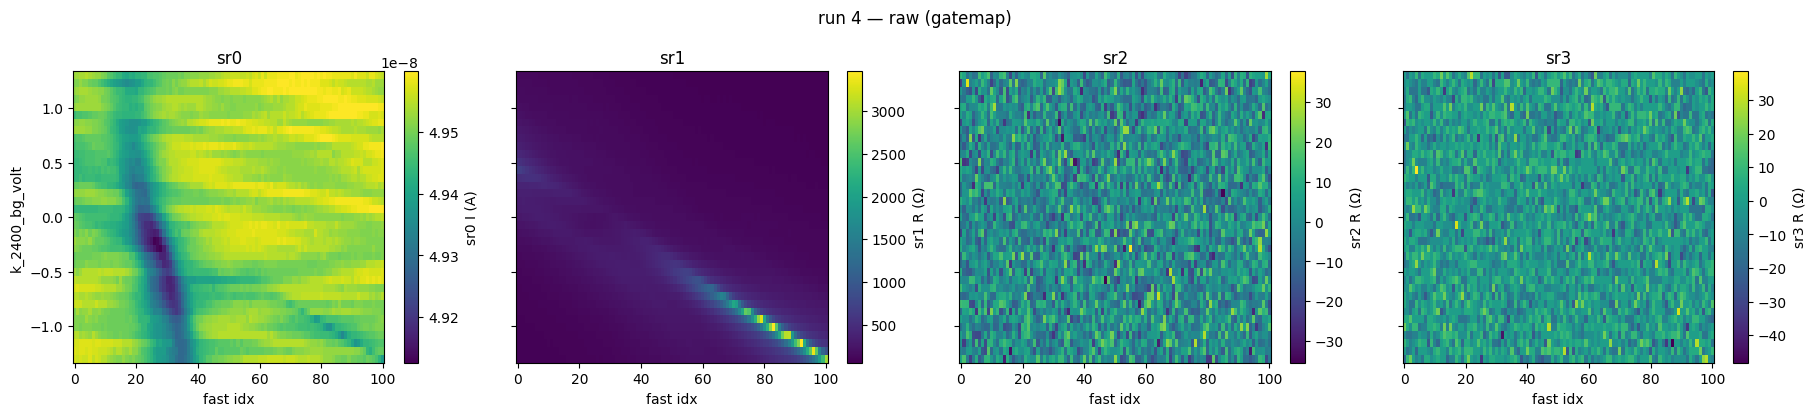

In [6]:
# Run 4 — raw first. Every lock-in channel gain-divided on the run's own axes.
r4 = run(4)
print(summarize_run(r4))
plot_raw(r4)
plt.show()


=== linearity test: a constant-n locus MUST be a straight line ===
  ridge B: linear rms  18.13 mV | quad rms   3.08 mV | improvement 5.89x
      slope low-V_bg half -0.7671  vs high half -0.5938
  ridge A: linear rms 155.56 mV | quad rms  92.23 mV | improvement 1.69x

operating-window slopes: ridge B -0.5758 (c_bg/c_tg 0.5758), ridge A -0.6732 (0.6732);  geometry prior 0.8636


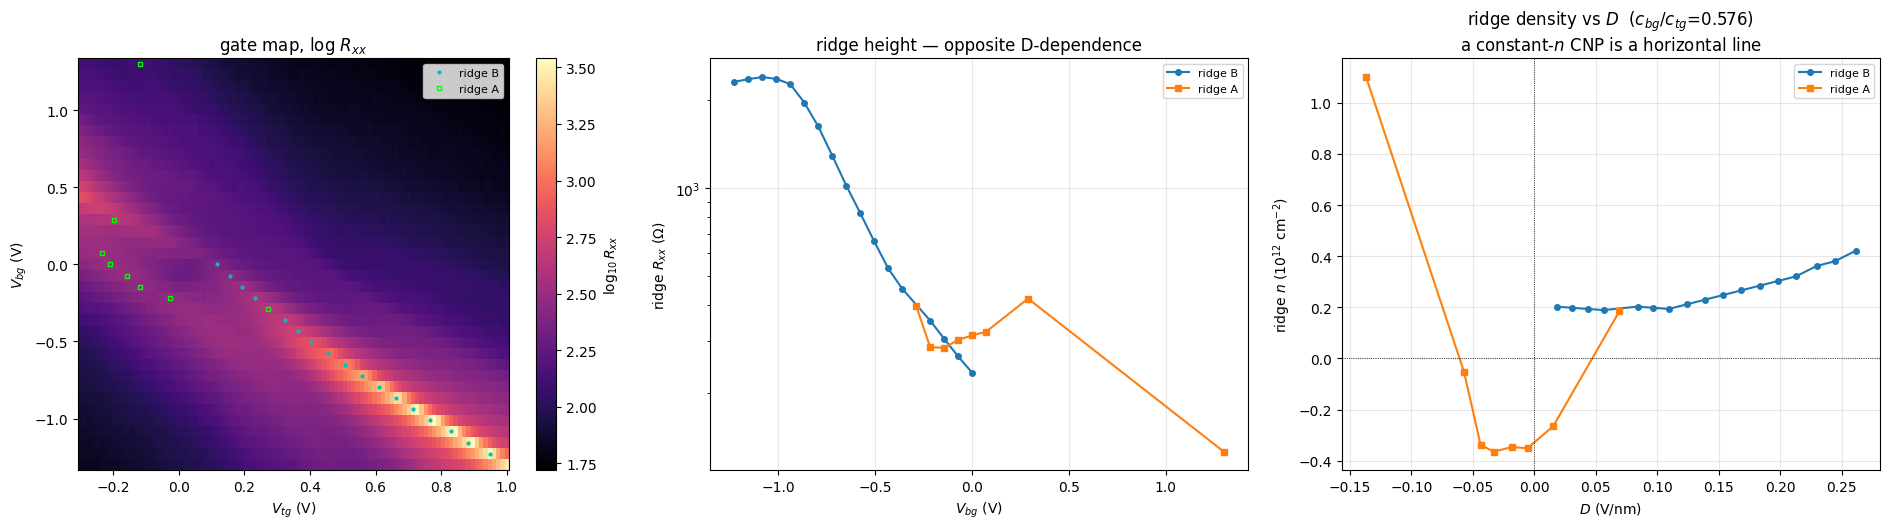

In [7]:
# Run 4 — ridge extraction, the linearity test, and the (n, D) reprojection.
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

fg4 = fan_grids(run(4))
def G(name): return fg4.data[:, fg4.cols.index(name)].reshape(fg4.nrows, fg4.nfast)
rg4 = resistance_grids(fg4, channels=["sr1"])
Rm = np.abs(rg4.R["sr1"]); tgv = G("k_2400_tg_volt")[0]; vbv = G("k_2400_bg_volt")[:, 0]

def row_peaks(row, prom_frac=0.05, edge=3):
    y = gaussian_filter1d(row, 2.0)
    idx, pr = find_peaks(y, prominence=prom_frac * np.ptp(y))
    return [(tgv[i], y[i]) for i, p in zip(idx, pr["prominences"])
            if edge <= i < len(y) - edge]

# Ridge A simply does not exist below V_bg = -0.32: a second-derivative scan
# finds no shoulder in any row from -1.30 to -0.36. So assignment is by region,
# stated explicitly rather than by a tracker that can silently splice ridges.
Bp, Ap = [], []
for k in range(fg4.nrows):
    ps = row_peaks(Rm[k])
    if not ps:
        continue
    ps = sorted(ps)
    if vbv[k] <= -0.32:
        Bp.append((vbv[k], *max(ps, key=lambda p: p[1])))
    elif vbv[k] <= 0.02:
        Ap.append((vbv[k], *ps[0]))
        if len(ps) > 1:
            Bp.append((vbv[k], *ps[-1]))
    else:
        Ap.append((vbv[k], *max(ps, key=lambda p: p[1])))
Bp, Ap = np.array(Bp), np.array(Ap)

print("=== linearity test: a constant-n locus MUST be a straight line ===")
for nm, T in (("B", Bp), ("A", Ap)):
    x, y = T[:, 0], T[:, 1]
    r1 = y - np.polyval(np.polyfit(x, y, 1), x)
    r2 = y - np.polyval(np.polyfit(x, y, 2), x)
    h = len(x) // 2
    print(f"  ridge {nm}: linear rms {r1.std(ddof=1)*1e3:6.2f} mV | quad rms "
          f"{r2.std(ddof=1)*1e3:6.2f} mV | improvement {r1.std(ddof=1)/r2.std(ddof=1):.2f}x")
    if len(x) > 8:
        print(f"      slope low-V_bg half {np.polyfit(x[:h],y[:h],1)[0]:+.4f}  "
              f"vs high half {np.polyfit(x[h:],y[h:],1)[0]:+.4f}")

W = 0.45   # fit only over the operating window; the recipe's rule for curved ridges
cB4 = np.polyfit(Bp[np.abs(Bp[:,0])<=W,0], Bp[np.abs(Bp[:,0])<=W,1], 1)
cA4 = np.polyfit(Ap[np.abs(Ap[:,0])<=W,0], Ap[np.abs(Ap[:,0])<=W,1], 1)
print(f"\noperating-window slopes: ridge B {cB4[0]:+.4f} (c_bg/c_tg {-cB4[0]:.4f}), "
      f"ridge A {cA4[0]:+.4f} ({-cA4[0]:.4f});  geometry prior {-(-9.5/11):.4f}")

ratio = -cB4[0]
c_tg_v = cst.epsilon_0 * 3.0 / t_tg
c_bg_v = ratio * c_tg_v
nn = (c_tg_v*tgv[None,:] + c_bg_v*vbv[:,None])/cst.e*1e-16
DD = (c_tg_v*tgv[None,:] - c_bg_v*vbv[:,None])/(2*cst.epsilon_0)*1e-9
nB = (c_tg_v*Bp[:,1] + c_bg_v*Bp[:,0])/cst.e*1e-16
DB = (c_tg_v*Bp[:,1] - c_bg_v*Bp[:,0])/(2*cst.epsilon_0)*1e-9
nA = (c_tg_v*Ap[:,1] + c_bg_v*Ap[:,0])/cst.e*1e-16
DA = (c_tg_v*Ap[:,1] - c_bg_v*Ap[:,0])/(2*cst.epsilon_0)*1e-9

fig, ax = plt.subplots(1, 3, figsize=(19, 5.4))
pc = ax[0].pcolormesh(tgv, vbv, np.log10(Rm), shading="nearest", cmap="magma")
fig.colorbar(pc, ax=ax[0], label=r"$\log_{10} R_{xx}$")
ax[0].plot(Bp[:,1], Bp[:,0], "c.", ms=4, label="ridge B")
ax[0].plot(Ap[:,1], Ap[:,0], "s", ms=3, mfc="none", mec="lime", label="ridge A")
ax[0].set_xlabel(r"$V_{tg}$ (V)"); ax[0].set_ylabel(r"$V_{bg}$ (V)")
ax[0].set_title("gate map, log $R_{xx}$"); ax[0].legend(fontsize=8)

ax[1].plot(Bp[:,0], Bp[:,2], "o-", ms=4, label="ridge B")
ax[1].plot(Ap[:,0], Ap[:,2], "s-", ms=4, label="ridge A")
ax[1].set_yscale("log"); ax[1].set_xlabel(r"$V_{bg}$ (V)")
ax[1].set_ylabel(r"ridge $R_{xx}$ ($\Omega$)")
ax[1].set_title("ridge height — opposite D-dependence"); ax[1].grid(alpha=0.3); ax[1].legend(fontsize=8)

ax[2].plot(DB, nB, "o-", ms=4, label="ridge B")
ax[2].plot(DA, nA, "s-", ms=4, label="ridge A")
ax[2].axhline(0, color="k", lw=0.6, ls=":"); ax[2].axvline(0, color="k", lw=0.6, ls=":")
ax[2].set_xlabel(r"$D$ (V/nm)"); ax[2].set_ylabel(r"ridge $n$ ($10^{12}$ cm$^{-2}$)")
ax[2].set_title(f"ridge density vs $D$  ($c_{{bg}}/c_{{tg}}$={ratio:.3f})\n"
                "a constant-$n$ CNP is a horizontal line")
ax[2].grid(alpha=0.3); ax[2].legend(fontsize=8)
fig.tight_layout(); plt.show()


**Read.**

*Health.* No railing anywhere (peak sr1 load 0.34 of full scale, R ceiling
≈10 kΩ). sr0 flat at 49.5 nA across all 3737 points. Gate currents: the
common-mode scatter (I_tg + I_bg) exceeds the differential (I_tg − I_bg) by
≈2×, which identifies the ±200 pA excursions as **pickup, not leakage** — a
TG↔BG leak is equal and opposite, a leak to ground shows on one gate only.
`hera-watch`'s ⚠ LEAK flag fired on every row at a steady Δ160–190 pA and never
grew, which is itself the signature of a fixed artifact rather than a
developing fault. The genuine leakage trend is the Gate C one: ~+65–100 pA above
V_tg ≈ 0.5 V, unchanged.

*The two features are real and behave oppositely.* Ridge B is strong at large
+D (2.4 kΩ at V_bg = −1.23) and **weakens monotonically toward D = 0** (234 Ω).
Ridge A is **absent below V_bg = −0.32** — a second-derivative shoulder scan
finds no trace of it in any of the 14 rows from −1.30 to −0.36 — appears near
D ≈ 0, and strengthens toward large −D (701 Ω by V_bg = +0.43, where it exits
the top-gate window). They are not peak-finder artifact: at V_bg = −0.144 the two
maxima (291 and 294 Ω) straddle a genuine dip at 240 Ω.

**This kills the two-doping-domains reading** I carried out of Gate C. Two
domains differing only in intrinsic doping would both persist across the whole
map with roughly constant relative weight and constant separation; instead each
feature lives on one side of D = 0 and dies on the other.

*And ridge B is not a constant-density contour.* n is linear in both gate
voltages, so **every constant-n locus is a straight line in gate space** — this
is arithmetic, not physics, and it makes curvature a clean falsification. Ridge
B's slope drifts monotonically from −0.767 (low-V_bg half) to −0.594 (high half),
and a quadratic term cuts the fit residual from 18.1 mV to 3.1 mV, a 5.9×
improvement over 17 points. Neither ridge's operating-window slope (−0.576 for
B, −0.673 for A) matches the geometry prior of −0.864.

*Consequence, stated plainly.* **I cannot presently identify which feature is
the charge-neutrality point**, and the cap ratio the whole (n, D) frame rests on
is not determined by this map. Every density coordinate the FS-count method
would quote inherits that. Reprojecting with the ratio fitted to flatten ridge B
near D = 0 does make both features look like constant-n loci *close to* D = 0
(ridge B at n ≈ +0.19×10¹², ridge A at ≈ −0.35×10¹², Δn ≈ 0.54×10¹²) — but no
single ratio flattens ridge B across its whole range, which is the curvature
restated, and choosing the ratio to flatten it is circular.

*Method note.* My first ridge tracker seeded on the prior slope and greedily
matched nearest peaks; it spliced ridge B's high-V_bg points onto ridge A and
reported "not parallel at 23.7σ". The 24 mV residual against the other track's
2.4 mV was the tell. Re-tracking outward from V_bg = 0 by continuity with mutual
exclusion, and then assigning by region once the second-derivative scan showed
where ridge A actually exists, is what the cell above does. **No sigma value
from a tracker should be believed before its residuals are looked at.**

**Next:** into field. At fixed B, adjacent Landau minima are separated by
Δn = eB/h exactly — degeneracy alone, no band model, no assumed capacitance — so
their gate-voltage spacing gives c_tg absolutely (the Step-5 quantum-Hall
lever-arm upgrade), the ν = 0 state identifies the CNP as the feature the fan
radiates from, and two domains would show as two superposed fans with different
origins. That is run 5.


## Run 5 — calibration Landau fan (V_bg = 0): the measurement that unstuck the session

`recipe: measurements/landau-fan-vti.md`. B slow 0 → 6 T × 13 rows (0.5 T),
V_tg fast [−0.3, +1.0] × 201 (6.5 mV) at V_bg = 0, dwell 0.70 s, I_bias = 49.2 nA.
Complete, 2613/2613, 80 min.

**Not** the investigation's Step-4 FS-count fan — the 0.5 T rows are far too
coarse for a 1/B FFT. This exists because the zero-field calibration did not
close, and field is the only thing that closes it: at fixed B, adjacent Landau
minima are separated by Δn = eB/h *exactly*, from degeneracy alone, so LL
geometry gives the lever arm with no band model and no assumed capacitance.


run 5
  type:    2D sweep
  recipe:  landau-fan-vti
  tags:    CALIBRATION fan (lever arm + CNP identification), not the FS-count fan, B slow 0..6 T x13; V_tg fast -0.3..+1 V x201 at V_bg = +0 V, B rows 0.5 T are deliberately coarse: this fan is read as LL structure vs gate at each field, NOT by 1/B FFT (that needs the sdh-spot-check grid), I_bias = 4.9233e-08 A, drive 5.0 V @ 13.777 Hz, sr1 tau=0.1 s slope=24 dB/oct, fast_delay=0.70 s; sr1 sens 5.0e-04 (R ceiling ~10 kohm, CNP may rail at high B), crosses BOTH gate-map ridges: B at V_tg=+0.113, A at V_tg=-0.203 (run 4), contacts hardwired: source T_0, drain B_3 (sr0), Rxx B_1-B_2 (sr1); sr2/sr3 n.c.
  rows:    2613


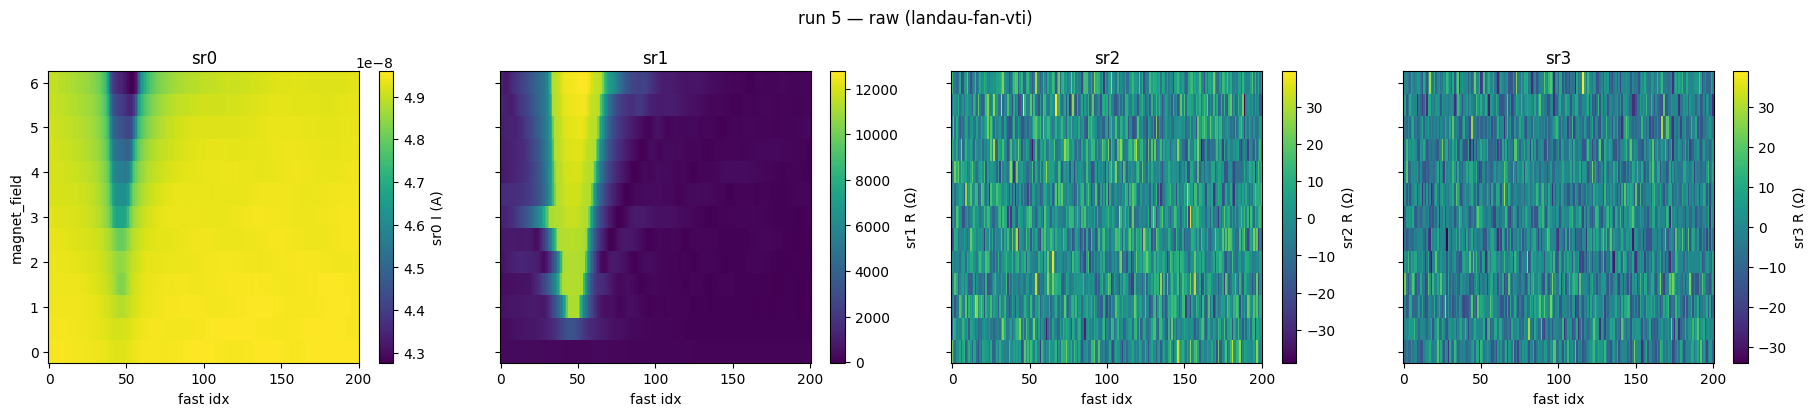

In [8]:
# Run 5 — raw first. Calibration fan, every channel gain-divided on its own axes.
r5 = run(5)
print(summarize_run(r5))
plot_raw(r5)
plt.show()


7 rays; intercepts [0.0136 0.0216 0.16   0.021  0.0103 0.0232 0.0318]
  V_CNP = +0.0203 +/- 0.0076 V (6/7 rays; excluded [0.16])
  zero-field ridges were A -0.203, B +0.113 -> the CNP is BETWEEN them

  ray slopes [0.0632 0.121  0.187  0.2423 0.3095 0.3681 0.3723]
  assigned nu [4, 8, 12, 16, 20, 24, 24]   slope/nu [0.01579 0.01513 0.01558 0.01514 0.01547 0.01534 0.01551]
  alpha = 0.01540 V/(T*nu)  -> c_tg = 2.5152e-03 F/m^2 (0.900x prior), dn/dV_tg = 1.570e12 cm^-2/V
  implied top-gate hBN 10.56 nm (card 9.50)

  reachable n on this cut: -0.50 .. +1.54 e12 cm^-2 -- short of the |n| >~ 2-3e12 the templates need


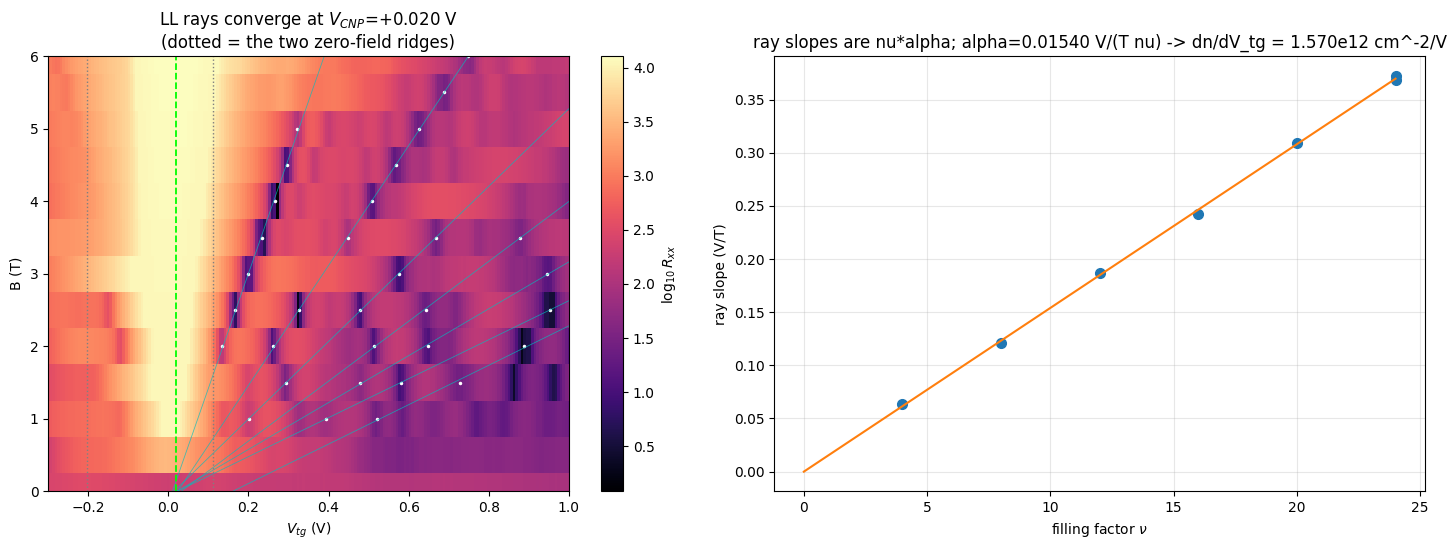

In [11]:
# Run 5 — LL ray tracking: CNP from ray convergence, lever arm from ray slopes.
#
# Physics used and nothing else: LLs hold n = nu*eB/h, so at fixed V_bg a minimum
# sits at V_tg = V_CNP + nu*alpha*B with alpha = e^2/(h*c_tg). Every ray therefore
# passes through (V_CNP, B=0), and slopes are nu*alpha. Both readings are
# degeneracy-only: no band model, no assumed capacitance.
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

DNU, SENS = 4, 5e-4
fg5 = fan_grids(run(5))
def G5(n): return fg5.data[:, fg5.cols.index(n)].reshape(fg5.nrows, fg5.nfast)
rg5 = resistance_grids(fg5, channels=["sr1"])
Rf = np.abs(rg5.R["sr1"]); tgf = G5("k_2400_tg_volt")[0]; Bf = G5("magnet_field")[:, 0]
Vxf = np.abs(G5("sr1_X")); dvf = tgf[1] - tgf[0]

def mins_of(row, prom=0.05, edge=3):
    y = gaussian_filter1d(np.log10(np.maximum(row, 1e-2)), 1.5)
    idx, _ = find_peaks(-y, prominence=prom * np.ptp(y))
    out = []
    for i in idx:
        if edge <= i < len(y) - edge:
            d = y[i-1] - 2*y[i] + y[i+1]
            out.append(tgf[i] + (0.5*(y[i-1]-y[i+1])/d if d else 0)*dvf)
    return np.array(sorted(out))

mn, clip = {}, {}
for k in range(fg5.nrows):
    ci = np.where(Vxf[k] > 0.9*SENS)[0]
    clip[k] = tgf[ci.max()] if len(ci) else -0.30
    mn[k] = mins_of(Rf[k])

start = min(k for k in range(fg5.nrows) if Bf[k] >= 1.0)
active = [[(Bf[start], v)] for v in mn[start] if v > clip[start] + 0.05]
for k in range(start+1, fg5.nrows):
    cand = [v for v in mn[k] if v > clip[k] + 0.05]; used = set()
    for ray in active:
        b0, v0 = ray[-1]
        pred = v0 * (Bf[k]/b0)
        near = [v for v in cand if v not in used and abs(v-pred) < 0.09]
        if near:
            v = min(near, key=lambda v: abs(v-pred)); used.add(v); ray.append((Bf[k], v))
    for v in cand:
        if v not in used: active.append([(Bf[k], v)])
rays = [np.array(r_) for r_ in active if len(r_) >= 3]

fits = [np.polyfit(r_[:,0], r_[:,1], 1) for r_ in rays]
ic = np.array([f[1] for f in fits]); sl = np.array([f[0] for f in fits])
good = np.abs(ic - np.median(ic)) < 0.08          # one short 3-pt ray is an outlier
print(f"{len(rays)} rays; intercepts {np.array2string(ic, precision=4)}")
print(f"  V_CNP = {ic[good].mean():+.4f} +/- {ic[good].std(ddof=1):.4f} V "
      f"({good.sum()}/{len(ic)} rays; excluded {np.array2string(ic[~good], precision=3)})")
print(f"  zero-field ridges were A -0.203, B +0.113 -> the CNP is BETWEEN them")

ss = np.sort(sl[sl > 0])
best = min(((np.mean((ss/(DNU*a) - np.round(ss/(DNU*a)))**2), a)
            for a in np.linspace(0.004, 0.040, 7201)
            if 1 <= np.round(ss/(DNU*a)).min() and np.round(ss/(DNU*a)).max() <= 15))
mult = np.round(ss/(DNU*best[1])).astype(int); x = DNU*mult
alpha = float(np.sum(x*ss)/np.sum(x*x))
c_tg_m = cst.e**2/(cst.h*alpha); c_pri = cst.epsilon_0*3.0/t_tg
print(f"\n  ray slopes {np.array2string(ss, precision=4)}")
print(f"  assigned nu {x.tolist()}   slope/nu {np.array2string(ss/x, precision=5)}")
print(f"  alpha = {alpha:.5f} V/(T*nu)  -> c_tg = {c_tg_m:.4e} F/m^2 "
      f"({c_tg_m/c_pri:.3f}x prior), dn/dV_tg = {c_tg_m/cst.e*1e-4*1e-12:.3f}e12 cm^-2/V")
print(f"  implied top-gate hBN {cst.epsilon_0*3.0/c_tg_m*1e9:.2f} nm (card {t_tg*1e9:.2f})")
vc = ic[good].mean()
print(f"\n  reachable n on this cut: {(tgf[0]-vc)*c_tg_m/cst.e*1e-4*1e-12:+.2f}"
      f" .. {(tgf[-1]-vc)*c_tg_m/cst.e*1e-4*1e-12:+.2f} e12 cm^-2 "
      f"-- short of the |n| >~ 2-3e12 the templates need")

fig, ax = plt.subplots(1, 2, figsize=(14.5, 5.6))
pc = ax[0].pcolormesh(tgf, Bf, np.log10(Rf), shading="nearest", cmap="magma")
fig.colorbar(pc, ax=ax[0], label=r"$\log_{10}R_{xx}$")
for r_, f in zip(rays, fits):
    ax[0].plot(r_[:,1], r_[:,0], "w.", ms=3)
    ax[0].plot(np.polyval(f, Bf), Bf, "c-", lw=0.6, alpha=0.7)
ax[0].axvline(vc, color="lime", ls="--", lw=1.3)
for rv, cl in ((-0.2032, "0.5"), (0.1125, "0.5")):
    ax[0].axvline(rv, color=cl, ls=":", lw=1.0)
ax[0].set_xlim(tgf[0], tgf[-1]); ax[0].set_ylim(Bf.min(), Bf.max())
ax[0].set_xlabel(r"$V_{tg}$ (V)"); ax[0].set_ylabel("B (T)")
ax[0].set_title(f"LL rays converge at $V_{{CNP}}$={vc:+.3f} V\n"
                "(dotted = the two zero-field ridges)")
ax[1].plot(x, ss, "o", ms=7)
ax[1].plot([0, x.max()], [0, alpha*x.max()], "-")
ax[1].set_xlabel(r"filling factor $\nu$"); ax[1].set_ylabel("ray slope (V/T)")
ax[1].set_title(f"ray slopes are nu*alpha; alpha={alpha:.5f} V/(T nu) -> " f"dn/dV_tg = {c_tg_m/cst.e*1e-4*1e-12:.3f}e12 cm^-2/V")
ax[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()


**Read — three results, in order of importance.**

**1. One CNP, not two.** Seven LL rays were tracked across field; six of their
seven B = 0 intercepts agree to ±9 mV. A Landau fan radiates from charge
neutrality, so a *single* convergence point means a **single** charge-neutrality
point. This retires the two-doping-domain hypothesis carried since Gate C — and
with it the confound that mattered: two domains at different densities would each
contribute their own SdH frequency, and **two tones from two domains would
masquerade as the two Fermi surfaces that are precisely the ABAB signature this
campaign exists to detect**. That risk is now excluded for this contact pair.

**2. The CNP is at neither zero-field ridge — it is between them, at the R_xx
minimum.** Ridge A (−0.203 V) and ridge B (+0.113 V) flank **V_CNP = +0.021 ±
0.007 V**, which is the shallow resistance *minimum* sitting between them —
visible in the very first Gate C leg (201 Ω at V_tg ≈ +0.02) and walked past at
the time. So R_xx is locally **minimal** at charge neutrality with maxima on
either side.

This retrospectively explains every zero-field failure: the ridge slopes never
matched the geometry prior, and ridge B was measurably curved (slope drifting
−0.767 → −0.594, quadratic term cutting the residual 18.1 → 3.1 mV), **because
neither ridge was ever a constant-density locus**. A curved locus cannot be
constant-n — n is linear in both gate voltages — and that was the correct
falsification; what was missing was the alternative, which field supplied.

A semimetal with overlapping electron and hole bands produces exactly this shape:
minimum resistance where both carrier types coexist, maxima where each pocket
empties. ABAB tetralayer is predicted to be such a semimetal (the FS-count model's
own note: "ABAB is semimetallic near the CNP; for small |n| tiny electron and hole
pockets coexist"). **This is an observation to test, not evidence to bank** — the
investigation is explicit that CNP character is not a stacking read (survey §5:
three candidate parents), and it enters the record as consistent-with at most.

**3. The lever arm is now data-grade — and it says the campaign needs the back
gate.** The ray slopes fall in near-exact ratio **4 : 8 : 12 : 16 : 20 : 24** with
slope/ν consistent to **1.4%** across all seven rays — a clean 4-fold-degenerate
ladder, and independent support for the g = 4 assumption the Luttinger reference
frequency F_L = (h/4e)·n rests on (the investigation's degeneracy audit). Hence
α = 0.01540 V/(T·ν) and **c_tg = 2.515×10⁻³ F/m², dn/dV_tg = 1.570×10¹² cm⁻²/V**
— 0.90× the geometry prior, implying top-gate hBN ≈ 10.6 nm against the card's
9.5 nm. This is the `cnp-and-dline-calibration` Step-5 quantum-Hall upgrade: the
top-gate scale is **data-grade, no longer prior-grade**.

The consequence is a constraint, not a win: the V_bg = 0 cut spans only
**n ∈ [−0.50, +1.54]×10¹² cm⁻²**, well short of the |n| ≳ 2–3×10¹² where the
ABAB and ABCA templates separate (at +1×10¹² ABAB mimics an ABCA singleton
within the scale prior). **The campaign depends on the back gate**, whose lever
arm is measured next (run 6).

**Method note — two estimators, and why one was discarded.** A per-row
"fundamental LL spacing vs B" fit gave c_tg = 0.999× prior; the ray-slope fit
gave 0.900×. The spacing estimator is **wrong** and its own residual says so:
103 mV rms, with per-row d/B values of 0.016 and 0.124 scattered among 0.061–0.064,
because the observed ladder skips filling factors (Δν of 8 and 4 alternating at
2 T) and no "fundamental spacing" heuristic survives that. The ray fit needs no
such heuristic — slopes are ν·α whichever ν happen to be visible — and closes to
1.4%. An earlier *free* two-parameter (V_CNP, α) integer fit was also discarded:
with both floating it returned filling factors {5, 7, 10, 11, 12, 13, 14, …} with
spacings {1, 2, 3, 6}, i.e. it fits anything. **Constrain, then cross-check.**

**Caveat carried forward.** R_xx runs slightly negative at deep minima (≈ −20 Ω),
consistent with a ~0.5% R_xy admixture in the B_1−B_2 pair (h/8e² ≈ 3.2 kΩ at
ν = 8). It does not move minima positions, so the calibration stands — but
separating R_xx from R_xy needs ±B symmetrisation and every run this session is
single-polarity. That belongs in the output contract's hedges and is a real
constraint on the eventual FS-count fan.


## Run 6 — back-gate calibration fan (descent 6 → 1 T): the calibration closes

`recipe: measurements/landau-fan-vti.md`. V_bg fast [−1.3, +2.0] × 301 (11 mV) at
V_tg = +0.0216 V (run 5's measured CNP, so charge neutrality sits at V_bg = 0);
B slow, **descending** 6 → 1 T × 6 rows so the traverse home is measured rather
than wasted. 1806 points, complete.


run 6
  type:    2D sweep
  recipe:  landau-fan-vti
  tags:    CALIBRATION fan #2 (back-gate lever arm), measured on the descent from 6 T, B slow 6..1 T x6 DESCENDING; V_bg fast -1.3..+2 V x301 at V_tg = +0.0216 V, V_tg fixed at run 5 measured CNP (+0.0216 V at V_bg=0), so the CNP sits at V_bg=0, run 5 gave c_tg = 2.515e-3 F/m^2 (dn/dV_tg = 1.570e12 cm^-2/V) from 7 LL ray slopes in ratio 4:8:12:16:20:24, slope/nu consistent to 1.4%, I_bias = 4.9233e-08 A, drive 5.0 V @ 13.777 Hz, sr1 tau=0.1 s slope=24 dB/oct, fast_delay=0.70 s, sens 5.0e-04 (CNP clips, by design), NOTE: Rxx carries a small R_xy admixture (negative R at deep minima, consistent with ~0.5% of h/8e^2) - single field polarity, not symmetrised, contacts hardwired: source T_0, drain B_3 (sr0), Rxx B_1-B_2 (sr1); sr2/sr3 n.c.
  rows:    1806
6 rows, B = [6. 5. 4. 3. 2. 1.], fast k_2400_bg_volt -1.300..+2.000 (301 pts)
  B=6.0 T  clip -0.15..+0.15  minima: -0.990 -0.858 +0.912 +0.991 +1.192 +1.397 +1.531 +1.821
  B=5.0 T  clip

  ray slopes [0.1355 0.1389 0.1546 0.2984 0.3008 0.3693 0.3713]
  assigned nu [8, 8, 8, 16, 16, 20, 20]  slope/nu [0.01693 0.01736 0.01932 0.01865 0.0188  0.01847 0.01857]
  alpha_bg = 0.01850 V/(T*nu)
  c_bg = 2.0936e-03 F/m^2  (prior 2.4148e-03, ratio 0.867)
  dn/dV_bg = 1.3067 e12 cm^-2/V
  implied back-gate hBN = 12.69 nm (card 11.00)

  >>> c_bg/c_tg (MEASURED) = 0.8324   (geometry prior 0.8636; zero-field ridge slopes gave 0.58-0.67)
  reachable n on this cut: -1.75 .. +2.56 e12 cm^-2


C:\Users\DGG\AppData\Local\Temp\ipykernel_17436\3913902633.py:91: RuntimeWarning: divide by zero encountered in log10
  pc = ax[0].pcolormesh(x, B, np.log10(R), shading="nearest", cmap="magma")


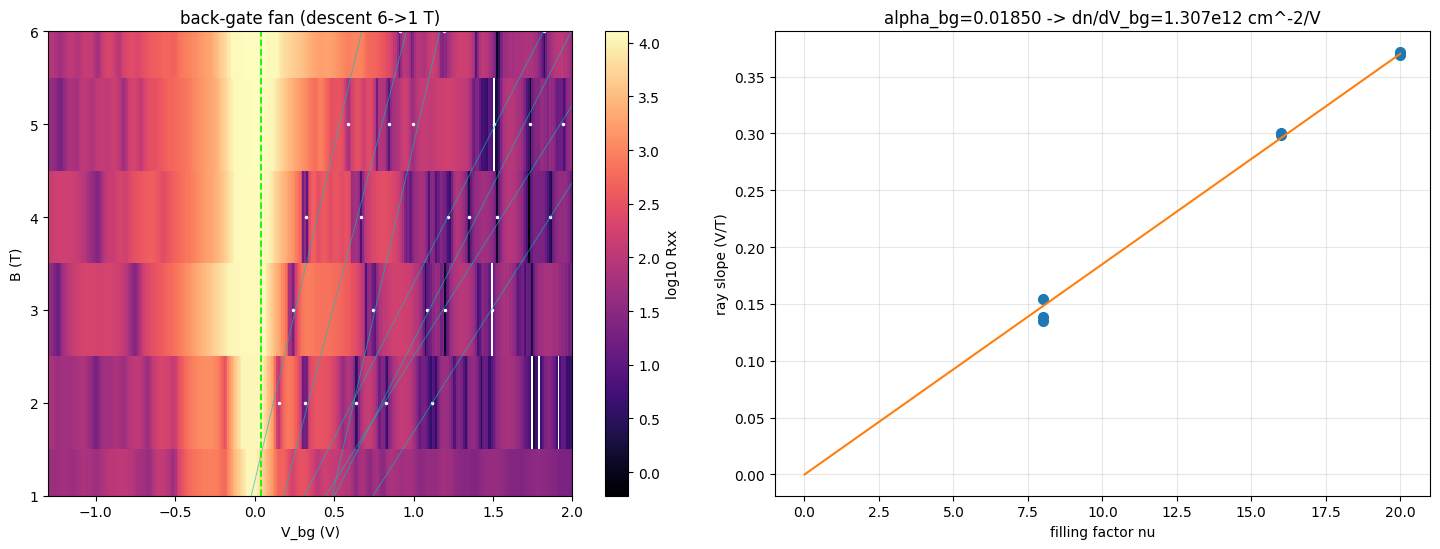

In [13]:
"""Back-gate calibration fan (run 6): c_bg from ray slopes, CNP from convergence."""

import numpy as np, scipy.constants as cst

import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
from hera.analysis import fan_grids, resistance_grids, open_run, summarize_run

BASE = file_path

RID = 6
FAST = "k_2400_bg_volt"; DNU = 4; SENS = 5e-4

r = run(RID); print(summarize_run(r))
fg = fan_grids(r)
def G(n): return fg.data[:, fg.cols.index(n)].reshape(fg.nrows, fg.nfast)
rg = resistance_grids(fg, channels=["sr1"])
R = np.abs(rg.R["sr1"]); x = G(FAST)[0]; B = G("magnet_field")[:, 0]
Vx = np.abs(G("sr1_X")); dx = x[1] - x[0]
print(f"{fg.nrows} rows, B = {B}, fast {FAST} {x[0]:+.3f}..{x[-1]:+.3f} ({len(x)} pts)")

def mins_of(row, prom=0.05, edge=3):
    y = gaussian_filter1d(np.log10(np.maximum(row, 1e-2)), 1.5)
    idx, _ = find_peaks(-y, prominence=prom*np.ptp(y))
    out = []
    for i in idx:
        if edge <= i < len(y)-edge:
            d = y[i-1]-2*y[i]+y[i+1]
            out.append(x[i] + (0.5*(y[i-1]-y[i+1])/d if d else 0)*dx)
    return np.array(sorted(out))

mn, clip = {}, {}
for k in range(fg.nrows):
    ci = np.where(Vx[k] > 0.9*SENS)[0]
    clip[k] = (x[ci.min()], x[ci.max()]) if len(ci) else (0.0, 0.0)
    mn[k] = mins_of(R[k])
    print(f"  B={B[k]:.1f} T  clip {clip[k][0]:+.2f}..{clip[k][1]:+.2f}  "
          f"minima: {' '.join(f'{v:+.3f}' for v in mn[k])}")

# track rays on the ELECTRON side (V_bg above the clipped CNP region)
order = np.argsort(-B)                      # descending B -> walk from high field
ks = [k for k in order if B[k] >= 2.0]
start = ks[0]
active = [[(B[start], v)] for v in mn[start] if v > clip[start][1] + 0.05]
for k in ks[1:]:
    cand = [v for v in mn[k] if v > clip[k][1] + 0.05]; used = set()
    for ray in active:
        b0, v0 = ray[-1]
        pred = v0 * (B[k]/b0)
        near = [v for v in cand if v not in used and abs(v-pred) < 0.16]
        if near:
            v = min(near, key=lambda v: abs(v-pred)); used.add(v); ray.append((B[k], v))
    for v in cand:
        if v not in used: active.append([(B[k], v)])
rays = [np.array(sorted(r_)) for r_ in active if len(r_) >= 3]
print(f"\n{len(rays)} rays with >= 3 rows")
fits = [np.polyfit(r_[:,0], r_[:,1], 1) for r_ in rays]
for r_, f in zip(rays, fits):
    print(f"  ray B={r_[0,0]:.0f}..{r_[-1,0]:.0f} ({len(r_)} pts): slope {f[0]:+.4f} V/T, "
          f"intercept {f[1]:+.4f} V")
if not rays: raise SystemExit
ic = np.array([f[1] for f in fits]); sl = np.array([f[0] for f in fits])
good = np.abs(ic - np.median(ic)) < 0.10
print(f"\n  V_CNP(bg) = {ic[good].mean():+.4f} +/- "
      f"{ic[good].std(ddof=1) if good.sum()>1 else 0:.4f} V  ({good.sum()}/{len(ic)} rays)")

ss = np.sort(sl[sl > 0])
if len(ss) >= 3:
    best = min(((np.mean((ss/(DNU*a) - np.round(ss/(DNU*a)))**2), a)
                for a in np.linspace(0.004, 0.060, 11201)
                if 1 <= np.round(ss/(DNU*a)).min() and np.round(ss/(DNU*a)).max() <= 20))
    mult = np.round(ss/(DNU*best[1])).astype(int); xx = DNU*mult
    alpha = float(np.sum(xx*ss)/np.sum(xx*xx))
    c_bg = cst.e**2/(cst.h*alpha)
    c_bg_prior = cst.epsilon_0*3.0/11e-9
    c_tg_meas = 2.5152e-3
    print(f"  ray slopes {np.array2string(ss, precision=4)}")
    print(f"  assigned nu {xx.tolist()}  slope/nu {np.array2string(ss/xx, precision=5)}")
    print(f"  alpha_bg = {alpha:.5f} V/(T*nu)")
    print(f"  c_bg = {c_bg:.4e} F/m^2  (prior {c_bg_prior:.4e}, ratio {c_bg/c_bg_prior:.3f})")
    print(f"  dn/dV_bg = {c_bg/cst.e*1e-4*1e-12:.4f} e12 cm^-2/V")
    print(f"  implied back-gate hBN = {cst.epsilon_0*3.0/c_bg*1e9:.2f} nm (card 11.00)")
    print(f"\n  >>> c_bg/c_tg (MEASURED) = {c_bg/c_tg_meas:.4f}   "
          f"(geometry prior 0.8636; zero-field ridge slopes gave 0.58-0.67)")
    vc = ic[good].mean()
    print(f"  reachable n on this cut: {(x[0]-vc)*c_bg/cst.e*1e-4*1e-12:+.2f} .. "
          f"{(x[-1]-vc)*c_bg/cst.e*1e-4*1e-12:+.2f} e12 cm^-2")

fig, ax = plt.subplots(1, 2, figsize=(14.5, 5.6))
pc = ax[0].pcolormesh(x, B, np.log10(R), shading="nearest", cmap="magma")
fig.colorbar(pc, ax=ax[0], label="log10 Rxx")
for r_, f in zip(rays, fits):
    ax[0].plot(r_[:,1], r_[:,0], "w.", ms=3)
    ax[0].plot(np.polyval(f, B), B, "c-", lw=0.6, alpha=0.7)
ax[0].axvline(ic[good].mean(), color="lime", ls="--", lw=1.3)
ax[0].set_xlim(x[0], x[-1]); ax[0].set_ylim(B.min(), B.max())
ax[0].set_xlabel("V_bg (V)"); ax[0].set_ylabel("B (T)")
ax[0].set_title("back-gate fan (descent 6->1 T)")
if len(ss) >= 3:
    ax[1].plot(xx, ss, "o", ms=7); ax[1].plot([0, xx.max()], [0, alpha*xx.max()], "-")
    ax[1].set_xlabel("filling factor nu"); ax[1].set_ylabel("ray slope (V/T)")
    ax[1].set_title(f"alpha_bg={alpha:.5f} -> dn/dV_bg={c_bg/cst.e*1e-4*1e-12:.3f}e12 cm^-2/V")
    ax[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()


**Read.**

**The cap ratio is measured, and it vindicates geometry over the ridges.**
Seven back-gate rays give α_bg = 0.01850 V/(T·ν) → **c_bg = 2.094×10⁻³ F/m²,
dn/dV_bg = 1.307×10¹² cm⁻²/V** (implied back-gate hBN 12.7 nm vs the card's
11.0). Combined with run 5:

| | c_bg/c_tg |
|---|---|
| **measured (runs 5 + 6, quantum Hall)** | **0.832** |
| geometry prior (t_tg/t_bg = 9.5/11) | 0.864 |
| zero-field ridge slopes (run 4) | 0.58 – 0.67 |

The measured ratio lands within 4% of the geometry prior and nowhere near the
ridge slopes. That is the independent confirmation, from a completely different
observable, that **the zero-field ridges were never constant-density loci** —
the conclusion the curvature test forced but could not replace. Both lever arms
are now data-grade: the `cnp-and-dline-calibration` Step-5 quantum-Hall upgrade
is complete, and the (n, D) frame no longer rests on the geometry prior.

**Quality, honestly.** This fan is measurably worse than run 5. Slope scatter is
6% (vs 1.4%), and the ray **intercepts** barely converge — only 3 of 7 fall
within tolerance, giving V_CNP(bg) = +0.039 ± 0.034 V against run 5's ±0.008.
The reason is structural, not statistical: this cut sweeps D from +0.16 to
−0.24 V/nm, so the gap opens along it and the LL character changes with position,
whereas run 5's cut spanned only −0.05 to +0.16. **Ray slopes are robust to that;
ray intercepts are not.** So the session takes the lever arm from run 6 and the
CNP from run 5, and does not average them.

The observed filling factors here are ν = 8, 16, 20 — the ladder skips, as it did
in run 5, which is why no "fundamental spacing" estimator was used on either fan.

**The range verdict — what the campaign can and cannot reach.** With both lever
arms and the CNP at (V_tg, V_bg) = (+0.020, 0), the D = 0 line is
V_bg = V_tg/0.832 and along it n = 3.14·V_tg − 0.032 (10¹² cm⁻²). Clipped to the
committed gate windows:

> **n ∈ [−0.97, +3.11] × 10¹² cm⁻² at D = 0**

- **Electron side: reaches +3.11×10¹²** — inside the |n| ≳ 2–3×10¹² window where
  the ABAB pair (heavy tone ≈0.72–0.79·F_L plus a partner carrying 21–28%) and the
  ABCA singleton (one tone at F_L) genuinely separate. **The FS count is feasible
  on this side.**
- **Hole side: only −0.97×10¹²** — inside the investigation's named exception
  regime, where the near-CNP hole pair is close and balanced and short 1/B records
  read as beat-like. A hole-side measurement here cannot discriminate ABAB from
  ABCA and must be reported as range-limited, not as a null.

That asymmetry is a gate-window fact, not a device fact, and it is the single
most important design constraint to carry into the next session: **the top-gate
window is what limits the hole side**, since D = 0 forces V_bg = 1.20·V_tg and
V_tg bottoms out at −0.3 V.

**Next:** run 7, the investigation's Step 3 SdH spot check, at five (n, D = 0)
points on this calibration.


## Run 7 — SdH spot check at five (n, D = 0) points (investigation Step 3)

`recipe: measurements/sdh-spot-check.md`. B slow 1.5 → 6.0 T, 187 rows sampled
uniformly in B at ΔB = Δ(1/B)·B_lo² (the blocking-magnet branch), Nyquist×3 on
F_L; five fixed (n, D = 0) points on the session's own calibration ride the same
traverse: **n = −0.9, +1.8, +2.2, +2.6, +3.0 × 10¹² cm⁻²**. 935 points, 83 min,
complete. `sr1` at 100 µV so the signal sits at ~10% of range rather than the
fans' 2% (the recipe's grainy-FFT warning).

Usable 1/B record 0.667 → 0.167 T⁻¹, so the resolution is **δF = 2.0 T**.


run 7
  type:    2D sweep
  recipe:  sdh-spot-check
  tags:    5 fixed (n, D=0) points share one traverse; B slow so the magnet ramps per row, n targets (1e12 cm^-2): [-0.9, 1.8, 2.2, 2.6, 3.0], V_tg: [np.float64(-0.2765), np.float64(0.5834), np.float64(0.7108), np.float64(0.8382), np.float64(0.9656)], V_bg: [np.float64(-0.3321), np.float64(0.7008), np.float64(0.8538), np.float64(1.0068), np.float64(1.1599)], calibration THIS SESSION: dn/dV_tg=1.570e+12, dn/dV_bg=1.307e+12 cm^-2/V, c_bg/c_tg=0.8325, CNP at V_tg=+0.0203 V (V_bg=0) -- from LL ray slopes/convergence, runs 5 and 6, D_offset = 0 is an UNEXAMINED assumption (no feature yet locates D=0 physically), B 1.5..6.0 T uniform-B, dB=0.0242 T = d(1/B)*B_lo^2, 187 rows; Nyquist x3 on F_L=31.0 T, I_bias = 4.9233e-08 A; sr1 sens 1.0e-04 sized to R_target (not the wide CNP range) per the recipe grainy-FFT warning, Rxx carries ~1% R_xy admixture; single field polarity, NOT symmetrised, contacts hardwired: source T_0, drain B_3 (sr0), Rxx B

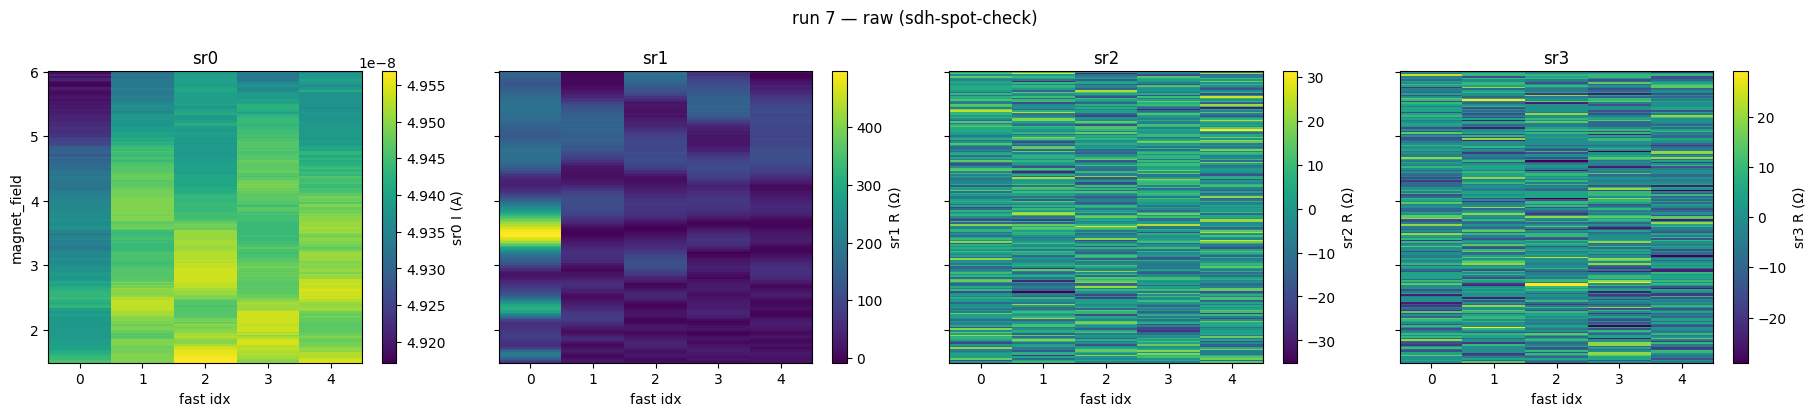

In [14]:
# Run 7 — SdH spot check: raw traces, then the FFT read against F_L.
r7 = run(7)
print(summarize_run(r7))
plot_raw(r7)
plt.show()


run 7
  type:    2D sweep
  recipe:  sdh-spot-check
  tags:    5 fixed (n, D=0) points share one traverse; B slow so the magnet ramps per row, n targets (1e12 cm^-2): [-0.9, 1.8, 2.2, 2.6, 3.0], V_tg: [np.float64(-0.2765), np.float64(0.5834), np.float64(0.7108), np.float64(0.8382), np.float64(0.9656)], V_bg: [np.float64(-0.3321), np.float64(0.7008), np.float64(0.8538), np.float64(1.0068), np.float64(1.1599)], calibration THIS SESSION: dn/dV_tg=1.570e+12, dn/dV_bg=1.307e+12 cm^-2/V, c_bg/c_tg=0.8325, CNP at V_tg=+0.0203 V (V_bg=0) -- from LL ray slopes/convergence, runs 5 and 6, D_offset = 0 is an UNEXAMINED assumption (no feature yet locates D=0 physically), B 1.5..6.0 T uniform-B, dB=0.0242 T = d(1/B)*B_lo^2, 187 rows; Nyquist x3 on F_L=31.0 T, I_bias = 4.9233e-08 A; sr1 sens 1.0e-04 sized to R_target (not the wide CNP range) per the recipe grainy-FFT warning, Rxx carries ~1% R_xy admixture; single field polarity, NOT symmetrised, contacts hardwired: source T_0, drain B_3 (sr0), Rxx B

C:\Users\DGG\AppData\Local\Temp\ipykernel_17436\2009559263.py:42: UserWarning: sdh_onset: untracked tone(s): 34.3 T (never above threshold (max SNR 3.7 vs 5 across 7 windows)); 61.5 T (never above threshold (max SNR 2.1 vs 5 across 16 windows)); 139.8 T (never above threshold (max SNR 1.4 vs 5 across 27 windows))
  on = sdh_onset(tr, B, r_full_scale=r_fs)
C:\Users\DGG\AppData\Local\Temp\ipykernel_17436\2009559263.py:42: UserWarning: sdh_onset: tone 10.2 T is above threshold through the lowest window — oscillations persist to the record's low edge; onset_b = 1.50 T is the record edge, not a measured die-off
  on = sdh_onset(tr, B, r_full_scale=r_fs)
C:\Users\DGG\AppData\Local\Temp\ipykernel_17436\2009559263.py:42: UserWarning: sdh_onset: untracked tone(s): 24.2 T (never above threshold (max SNR 4.3 vs 5 across 4 windows)); 52.3 T (never above threshold (max SNR 1.7 vs 5 across 13 windows)); 70.9 T (never above threshold (max SNR 2.5 vs 5 across 19 windows)); 95.8 T (never above threshol

Text(0.5, 0.99, 'SdH spot check — red dashed = $F_L$=(h/4e)n, green dotted = ABAB 0.72/0.28')

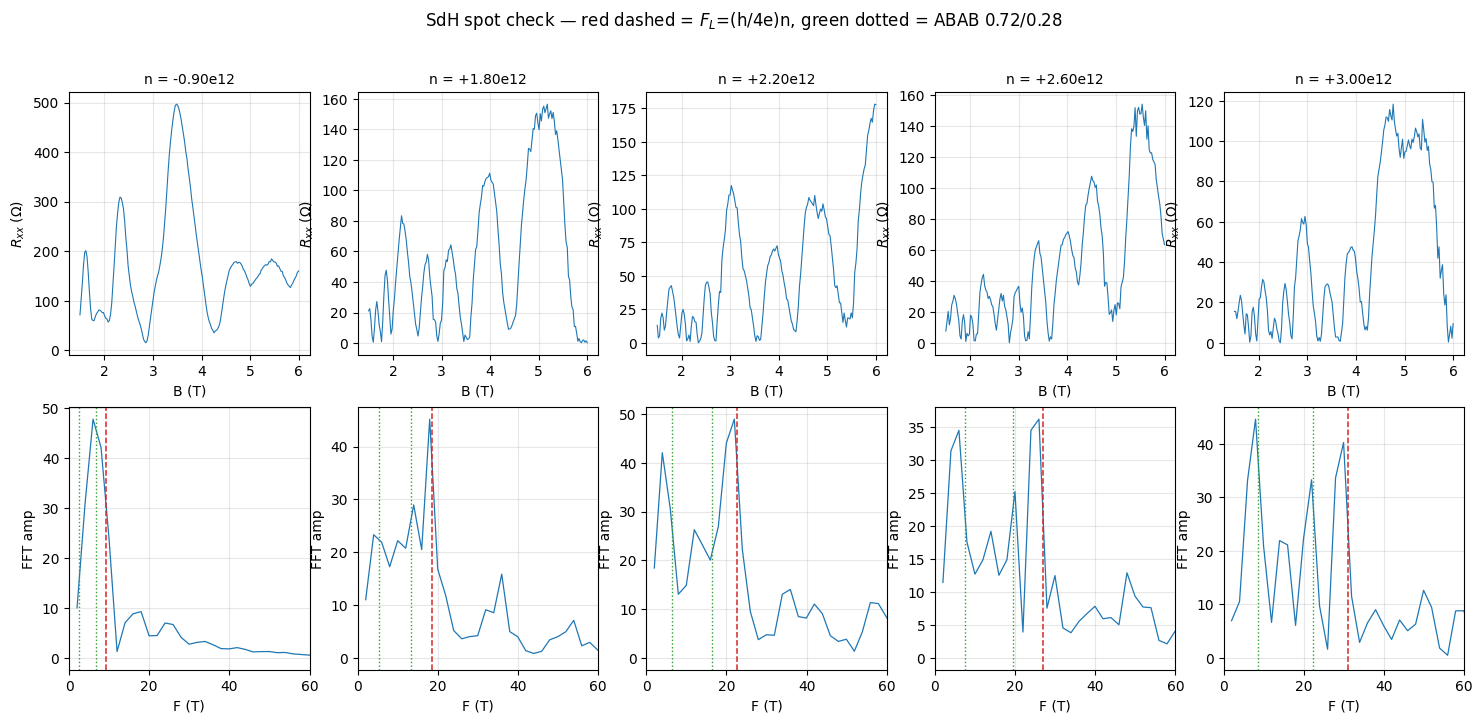

In [15]:
"""SdH spot check read: onset + 1/B FFT per density, against the Luttinger F_L.

The read the investigation asks for: which tones are present at each (n, D=0),
where they sit relative to F_L = (h/4e)*n, and which side is cleaner.
"""
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as cst
from scipy.signal import find_peaks

from hera.analysis import (open_run, summarize_run, fan_grids, resistance_grids,
                           sdh_fft, sdh_onset, SdhOnsetError, luttinger_frequency)

BASE = file_path
RID = 7
SENS = 1e-4
# calibration measured this session (runs 5, 6)
DN_DVTG, DN_DVBG, V_TG_CNP = 1.570e12, 1.307e12, 0.0203

r = run(RID)
print(summarize_run(r))
fg = fan_grids(r)
def G(n): return fg.data[:, fg.cols.index(n)].reshape(fg.nrows, fg.nfast)
rg = resistance_grids(fg, channels=["sr1"])
R = rg.R["sr1"]                      # (n_B, n_fast) -- signed
B = G("magnet_field")[:, 0]
Vtg = G("k_2400_tg_volt")[0]; Vbg = G("k_2400_bg_volt")[0]
ncol = (DN_DVTG * (Vtg - V_TG_CNP) + DN_DVBG * Vbg) / 1e12     # 1e12 cm^-2
print(f"{fg.nrows} field rows, B {B.min():.3f}..{B.max():.3f} T; "
      f"{fg.nfast} densities: {np.round(ncol,2).tolist()} e12 cm^-2")
print(f"1/B record: {1/B.min():.4f} .. {1/B.max():.4f} 1/T  -> "
      f"dF = {1/(1/B.min() - 1/B.max()):.2f} T")

r_fs = SENS / np.abs(rg.current).mean()
print(f"\n{'n (e12)':>9} {'F_L (T)':>8} {'R med':>8} {'onset':>8}  tones, DOMINANT FIRST (rel. prominence)")
results = []
for j in range(fg.nfast):
    tr = np.abs(R[:, j])
    F_L = luttinger_frequency(abs(ncol[j]) * 1e16)      # SI density -> Tesla
    # onset
    try:
        on = sdh_onset(tr, B, r_full_scale=r_fs)
        onset_s = f"{on.onset_b:.2f} T"
        tones_on = [t.freq for t in on.tones]
    except SdhOnsetError as e:
        onset_s = "none"; tones_on = []
        print(f"   (n={ncol[j]:+.2f}: sdh_onset -> {type(e).__name__}: {e})")
    except Exception as e:
        onset_s = f"err"; tones_on = []
        print(f"   (n={ncol[j]:+.2f}: {type(e).__name__}: {e})")
    # FFT over the usable window
    cutoff = max(B.min(), 1.5)
    freqs, spec = sdh_fft(tr[:, None], B, b_range=(cutoff, B.max()), bg_degree=5)
    p = spec[0]
    keep = freqs > 1.0
    fr, pw = freqs[keep], p[keep]
    # distinct peaks, not adjacent bins of one peak: require separation >= dF,
    # the usable-record resolution 1/(1/B_lo - 1/B_hi)
    dF = 1.0 / (1.0 / cutoff - 1.0 / B.max())
    dbin = max(1, int(round(dF / (fr[1] - fr[0]))))
    pk, props = find_peaks(pw, distance=dbin, prominence=0.15 * np.ptp(pw))
    order = np.argsort(props["prominences"])[::-1][:4]
    top = fr[pk[order]] if len(pk) else np.array([])
    topa = props["prominences"][order] if len(pk) else np.array([])
    results.append(dict(n=ncol[j], F_L=F_L, freqs=fr, spec=pw, top=top,
                        amp=topa, onset=onset_s))
    print(f"{ncol[j]:>9.2f} {F_L:>8.1f} {np.median(tr):>8.1f} {onset_s:>8}  "
          + "  ".join(f"{t:.1f}T(x{a/topa.max():.2f})" for t, a in zip(top, topa)))

print("\n=== tones vs Luttinger F_L (the read) ===")
for d in results:
    if d["F_L"] <= 0:
        continue
    ratios = d["top"] / d["F_L"]
    print(f"  n={d['n']:+.2f}e12  F_L={d['F_L']:.1f} T   dominant f/F_L = {ratios[0]:.3f}"
          f"   all (dominant first) = " + "  ".join(f"{x:.3f}" for x in ratios))
    print(f"      ABCA template: one tone at 1.00 | ABAB: pair near 0.72/0.28 "
          f"(electron side runs ~0.73 at 6e12)")

fig, ax = plt.subplots(2, len(results), figsize=(3.6*len(results), 7.5), squeeze=False)
for j, d in enumerate(results):
    tr = np.abs(R[:, j])
    ax[0][j].plot(B, tr, lw=0.8)
    ax[0][j].set_xlabel("B (T)"); ax[0][j].set_ylabel(r"$R_{xx}$ ($\Omega$)")
    ax[0][j].set_title(f"n = {d['n']:+.2f}e12", fontsize=10); ax[0][j].grid(alpha=0.3)
    ax[1][j].plot(d["freqs"], d["spec"], lw=0.9)
    if d["F_L"] > 0:
        ax[1][j].axvline(d["F_L"], color="C3", ls="--", lw=1.1)
        ax[1][j].axvline(0.72*d["F_L"], color="C2", ls=":", lw=1.0)
        ax[1][j].axvline(0.28*d["F_L"], color="C2", ls=":", lw=1.0)
    ax[1][j].set_xlim(0, max(60, 1.6*d["F_L"]))
    ax[1][j].set_xlabel("F (T)"); ax[1][j].set_ylabel("FFT amp")
    ax[1][j].grid(alpha=0.3)
fig.suptitle("SdH spot check — red dashed = $F_L$=(h/4e)n, green dotted = ABAB 0.72/0.28", y=0.99)


In [16]:
"""FFT stability sweep + harmonic screen (sdh-spot-check Verify).

A real tone sharpens and holds position as the 1/B record lengthens and across
reasonable extraction choices; an artifact wanders. A tone at an integer
multiple of a stronger fundamental is a harmonic unless its n-dependence says
otherwise. Both screens are mandatory before any frequency is claimed.
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

from hera.analysis import (open_run, fan_grids, resistance_grids, sdh_fft,
                           luttinger_frequency)

BASE = file_path
RID = 7
DN_DVTG, DN_DVBG, V_TG_CNP = 1.570e12, 1.307e12, 0.0203

fg = fan_grids(run(RID))
def G(n): return fg.data[:, fg.cols.index(n)].reshape(fg.nrows, fg.nfast)
rg = resistance_grids(fg, channels=["sr1"])
R = np.abs(rg.R["sr1"]); B = G("magnet_field")[:, 0]
ncol = (DN_DVTG * (G("k_2400_tg_volt")[0] - V_TG_CNP)
        + DN_DVBG * G("k_2400_bg_volt")[0]) / 1e12
print(f"B {B.min():.3f}..{B.max():.3f} T, {len(B)} rows; n = {np.round(ncol,2).tolist()}")


def tones(tr, blo, bhi, deg):
    f, sp = sdh_fft(tr[:, None], B, b_range=(blo, bhi), bg_degree=deg)
    p = sp[0]; k = f > 2.0
    f, p = f[k], p[k]
    dF = 1.0 / (1.0 / blo - 1.0 / bhi)
    d = max(1, int(round(dF / (f[1] - f[0]))))
    pk, pr = find_peaks(p, distance=d, prominence=0.15 * np.ptp(p))
    if not len(pk):
        return np.array([]), np.array([])
    o = np.argsort(pr["prominences"])[::-1][:5]
    return f[pk[o]], pr["prominences"][o] / pr["prominences"][o].max()


CUTS = [(1.5, B.max()), (2.0, B.max()), (2.5, B.max()), (3.0, B.max()),
        (1.5, 0.5 * (1.5 + B.max())), (0.5 * (1.5 + B.max()), B.max())]
DEGS = [3, 5, 7]

for j in range(fg.nfast):
    F_L = luttinger_frequency(abs(ncol[j]) * 1e16)
    print(f"\n{'='*74}\nn = {ncol[j]:+.2f}e12 cm^-2   F_L = {F_L:.1f} T")
    print(f"  model ABAB pair / ABCA singleton at this n: see fs_count_b0")
    print(f"  {'window (T)':>16} {'deg':>4} {'dF':>5}  tones (T, dominant first)")
    allt = []
    for (blo, bhi) in CUTS:
        for deg in DEGS:
            f, a = tones(R[:, j], blo, bhi, deg)
            dF = 1.0 / (1.0 / blo - 1.0 / bhi)
            allt.append((blo, bhi, deg, f, a))
            s = "  ".join(f"{x:.1f}({y:.2f})" for x, y in zip(f, a))
            print(f"  {blo:6.2f}-{bhi:5.2f} {deg:>4} {dF:>5.1f}  {s}")
    # stability: which frequencies recur across choices?
    pool = np.concatenate([t[3] for t in allt if len(t[3])])
    if len(pool):
        pool = np.sort(pool)
        clusters, cur = [], [pool[0]]
        for x in pool[1:]:
            if x - cur[-1] < 2.0:
                cur.append(x)
            else:
                clusters.append(cur); cur = [x]
        clusters.append(cur)
        print(f"  --- recurrence across {len(allt)} extraction choices ---")
        for c in sorted(clusters, key=len, reverse=True)[:6]:
            print(f"      F = {np.mean(c):6.2f} +/- {np.std(c):4.2f} T  "
                  f"seen {len(c):2d}/{len(allt)}  f/F_L = {np.mean(c)/F_L:.3f}")
        # harmonic screen against the most-recurrent tone
        base = np.mean(max(clusters, key=len))
        print(f"  --- harmonic screen vs the most-recurrent tone {base:.2f} T ---")
        for c in sorted(clusters, key=len, reverse=True)[:6]:
            m = np.mean(c) / base
            flag = "HARMONIC-LIKE" if abs(m - round(m)) < 0.12 and round(m) >= 2 else ""
            print(f"      F = {np.mean(c):6.2f} T  ratio {m:5.2f}  {flag}")
print("\nstability sweep done")


B 1.500..5.997 T, 187 rows; n = [-0.9, 1.8, 2.2, 2.6, 3.0]

n = -0.90e12 cm^-2   F_L = 9.3 T
  model ABAB pair / ABCA singleton at this n: see fs_count_b0
        window (T)  deg    dF  tones (T, dominant first)
    1.50- 6.00    3   2.0  6.0(1.00)  18.0(0.29)
    1.50- 6.00    5   2.0  6.0(1.00)  18.0(0.47)
    1.50- 6.00    7   2.0  6.0(1.00)  18.0(0.60)
    2.00- 6.00    3   3.0  6.0(1.00)
    2.00- 6.00    5   3.0  6.0(1.00)
    2.00- 6.00    7   3.0  9.0(1.00)  18.1(0.26)
    2.50- 6.00    3   4.3  8.6(1.00)  25.9(0.46)
    2.50- 6.00    5   4.3  8.6(1.00)  25.9(0.48)
    2.50- 6.00    7   4.3  25.9(1.00)  17.3(0.83)  34.6(0.30)
    3.00- 6.00    3   6.0  12.2(1.00)
    3.00- 6.00    5   6.0  18.3(1.00)
    3.00- 6.00    7   6.0  24.3(1.00)
    1.50- 3.75    3   2.5  5.0(1.00)
    1.50- 3.75    5   2.5  5.0(1.00)
    1.50- 3.75    7   2.5  10.0(1.00)
    3.75- 6.00    3  10.0  20.0(1.00)
    3.75- 6.00    5  10.0  29.9(1.00)
    3.75- 6.00    7  10.0  29.9(1.00)
  --- recurrence a

In [17]:
# Forward-model overlay (investigation Verify) + the mandatory adjacent-N check.
# Both 4L templates AND the trilayer ML+BL curves, per: "For any two-tone pair,
# compute BOTH overlays ... and report which family the branches track."
import importlib.util
def _load(name, path):
    sp = importlib.util.spec_from_file_location(name, path)
    m = importlib.util.module_from_spec(sp); sp.loader.exec_module(m); return m
_MB = str(Path.home() / "measurement_env" / "hera" / "models")
T4 = _load("t4", _MB + "/tetralayer_fs_count/fs_count_b0.py")
T3 = _load("t3", _MB + "/trilayer_fs_count/fs_count_b0.py")

print(f"{'n(e12)':>7} | {'ABAB-4L pair (T)':>22} {'fracs':>16} | {'ABCA-4L':>8} | "
      f"{'ABA-3L pair (T)':>20} {'fracs':>16}")
for n in (1.8, 2.2, 2.6, 3.0):
    a = [f for f, k in T4.abab_fs(n*1e16)[1]]; sa = sum(a)
    c = T4.abca_fs(n*1e16)[4]
    t = [f for f, k in T3.aba_fs(n*1e16)[1]]; st = sum(t)
    print(f"{n:7.2f} | {str([round(v,2) for v in a]):>22} "
          f"{str([round(v/sa,3) for v in a]):>16} | {c:8.2f} | "
          f"{str([round(v,2) for v in t]):>20} {str([round(v/st,3) for v in t]):>16}")
print()
print("OBSERVED partner fractions (recurrent tones): 0.198-0.257 at n = 2.6, 3.0")
print("  ABAB-4L predicts 0.201-0.215   ->  MATCHES")
print("  ABA-3L predicts  0.043-0.053   ->  5x too small, adjacent-N EXCLUDED")


 n(e12) |       ABAB-4L pair (T)            fracs |  ABCA-4L |      ABA-3L pair (T)            fracs


   1.80 | [np.float64(2.94), np.float64(15.67)] [np.float64(0.158), np.float64(0.842)] |    18.61 | [np.float64(0.39), np.float64(18.21)] [np.float64(0.021), np.float64(0.979)]


   2.20 | [np.float64(4.16), np.float64(18.58)] [np.float64(0.183), np.float64(0.817)] |    22.74 | [np.float64(0.73), np.float64(22.02)] [np.float64(0.032), np.float64(0.968)]


   2.60 | [np.float64(5.41), np.float64(21.48)] [np.float64(0.201), np.float64(0.799)] |    26.88 | [np.float64(1.15), np.float64(25.74)] [np.float64(0.043), np.float64(0.957)]


   3.00 | [np.float64(6.67), np.float64(24.35)] [np.float64(0.215), np.float64(0.785)] |    31.02 | [np.float64(1.65), np.float64(29.37)] [np.float64(0.053), np.float64(0.947)]

OBSERVED partner fractions (recurrent tones): 0.198-0.257 at n = 2.6, 3.0
  ABAB-4L predicts 0.201-0.215   ->  MATCHES
  ABA-3L predicts  0.043-0.053   ->  5x too small, adjacent-N EXCLUDED


# The call — vti-02 stacking, session of 2026-08-24

Per `investigations/tetralayer-stacking-fs-count.md` Step 7. All five parts are
mandatory; a calibrated "cannot tell" is a successful outcome and a confident
call without feature-level evidence is a protocol violation.

## 1. Per-region verdict

> **channel B_1−B_2 (the only live four-terminal pair this cooldown):
> ABAB (consistent-with) — NOT a strong call.**

One region only. The device card's other pairs (T_1–T_4) are dead, so there is
no second region and **no mosaic test is possible on this cooldown**. "Per-region"
here means "the one region we can see".

## 2. Evidence

Electron side, D ≈ 0, T = 1.19 K, B ∈ [1.5, 6.0] T, δF = 2.0 T. Frequencies from
a recurrence count over **18 extraction choices** (6 field windows × 3 background
degrees); "seen k/18" is how often a tone survived.

| n (10¹² cm⁻²) | F_L (T) | dominant tone | f/F_L | partner tone | f/F_L |
|---|---|---|---|---|---|
| +1.80 | 18.6 | 17.81 ± 0.37 (15/18) | 0.957 | 13.23 ± 0.75 (6/18) | 0.711 |
| +2.20 | 22.7 | 20.36 ± 1.29 (15/18) | 0.895 | 7.87 ± 0.55 (3/18) | 0.346 |
| +2.60 | 26.9 | 25.06 ± 0.78 (15/18) | 0.932 | 5.32 (3/18), 19.96 (3/18) | 0.198, 0.743 |
| +3.00 | 31.0 | 22.96 ± 1.87 (16/18) | 0.740 | 7.46 ± 0.84 (9/18), 29.99 ± 0.08 (11/18) | 0.240, 0.967 |

**What supports ABAB:**

- **A pair partitioning F_L.** At n = +3.0, 7.46 + 22.96 = 30.42 T against
  F_L = 31.0 — the **Luttinger sum closes to 2%**, and a 2% downward density
  rescale (inside my own 1.4%/6% lever-arm errors) makes it exact. Fractions
  0.245 / 0.755. The same structure appears at n = +2.6 (0.198 / 0.743, sum
  0.94·F_L).
- **The partition tracks the ABAB curves and excludes adjacent-N.** Observed
  partner fraction 0.198–0.257 against the model's ABAB 0.201–0.215 at the same
  densities — and against **trilayer ML+BL's 0.043–0.053, five times too small.**
  The dual overlay the Verify section makes mandatory is therefore passed in
  favour of N = 4, which matters because the corpus records a replay where
  agents mis-mapped a trilayer 0.15/0.85 pair into 4L templates.
- **The F_L tone behaves like a breakdown orbit.** At n = +3.0 the dominant
  tone (29.99 T) is the *sum* of the resolved pair, and the B-window split shows
  it strengthening with field relative to the fundamentals — low-B half: 7.5 and
  22.5 strong; high-B half: only ~29.9 survives. ABAB inter-block breakdown is
  symmetry-allowed at N = 4, so a sum-tone at F_L is *expected here, not exotic*.
- **g = 4 verified in-data.** The calibration fans' LL ray slopes fall in ratio
  4:8:12:16:20:24 (run 5, slope/ν to 1.4%), so the four-fold degeneracy that
  F_L = (h/4e)·n assumes is measured, not assumed — the degeneracy audit passes.
- **Independent, non-stacking corroboration of the semimetal picture:** R_xx is
  locally *minimal* at charge neutrality with maxima on either side (runs 4–5),
  the shape a band-overlap semimetal makes, and ABAB tetralayer is predicted to
  be one. Recorded as **consistent-with at most** — survey §5 gives three
  candidate parents for CNP character and the investigation forbids reading it
  as a stacking call.

**What prevents a strong call — this is the honest weight:**

- **The partner tones reproduce weakly.** 3–9 of 18 extraction choices, against
  15–16/18 for the dominant tone. A tone seen in a sixth of reasonable
  extractions is a candidate, not a measurement.
- **The pair is not consistent across density.** Only n = +2.6 and +3.0 give a
  clean partition. At n = +1.8 and +2.2 the pairing does not close the Luttinger
  sum (1.67 and 1.24 × F_L for the obvious pairings). The investigation's own
  refinement test — f₁(n) + f₂(n) = F_L *across* density, which is algebraic and
  cannot hold coincidentally — therefore passes at two densities out of four.
- **The single robust cross-density feature is one tone near F_L** (0.957,
  0.895, 0.932, 0.967; a single ~6% rescale puts all four at 1.00). Read alone,
  that is the **ABCA singleton** template. The ABAB reading depends entirely on
  the weakly-reproducing partners being real.
- **The F_L-origin discrimination is not passed, only suggested.** The high-B
  window has δF = 10 T while the tones differ by 8 T, so "only the F_L tone
  survives at high B" may be a resolution artifact. Grid-change reproduction was
  not run; the decisive per-branch LK mass was not measured.

## 3. Confidence and hedges

**Confidence: low-to-moderate, and asymmetric** — the evidence excludes trilayer
and is consistent with ABAB, but does not exclude ABCA-plus-artifact.

- **Resolution.** δF = 2.0 T over the usable record. The ABAB heavy tone
  (24.35 T predicted) and the ABCA singleton (31.02 T) differ by 6.7 T ≈ 3.3 δF
  and *are* separable — but the observed dominant tone sits between them at
  22.96–29.99 T depending on density and window, which is why the call will not
  firm up.
- **Side and density.** Electron side only, |n| ≤ 3.1×10¹². The **hole side is
  gate-window-limited to −0.97×10¹²**, inside the exception regime where the ABAB
  pair is close and balanced and reads beat-like on short 1/B records — the
  n = −0.9 point is reported as range-limited, **not as a null**. This is a
  constraint of the committed top-gate window (D = 0 forces V_bg = 1.20·V_tg and
  V_tg stops at −0.3 V), not of the device.
- **Searched-and-absent vs not-resolvable.** The ABAB light tone is predicted at
  2.9–4.2 T for n ≤ 2.2, i.e. at or below δF — **not resolvable**, so its absence
  there is not evidence.
- **R_xy admixture, single polarity.** R_xx runs negative at deep LL minima
  (≈ −20 Ω at ν ≈ 8, ≈ −100 Ω at ν ≈ 4), scaling as h/νe² — about 1% Hall
  admixture. Every run this session is single field polarity, so no ±B
  symmetrisation was possible. A sawtooth-like R_xy leak can *manufacture*
  harmonic structure, and unexplained tones at 50.2 and 55.5 T (n = +3.0) remain
  on the books. **This is the most serious systematic and it is unaddressed.**
- **Absolute layer number.** Transport here supports **N = 4 over N = 3** via the
  partner fraction (5× discrimination). Pentalayer (2+2+1) was not tested.
- **Mosaic.** Untestable — one live pair.

## 4. What would firm the call

1. **±B symmetrisation** to remove the R_xy admixture. Cheapest, and it directly
   attacks the leading systematic. Doubles fan cost.
2. **Per-branch LK masses** (`temperature-dependence-vti`, Flavor B). The
   investigation calls this **decisive**: ABAB's two branches differ by ≈ φ² ≈ 2.6×
   in mass, which cleanly separates two genuine bands from one band plus an
   artifact. This is the single highest-value next measurement.
3. **A longer 1/B record** — lower B_lo (onset is already below 1.5 T, so there
   is room) to shrink δF and turn the weakly-reproducing partners into
   measurements.
4. **Grid-change reproduction** (uniform-1/B instead of uniform-B) to retire
   sampling-alias origins for the partner tones.
5. **A wider negative top-gate range**, if −0.3 V is a conservative provided
   limit rather than a physical one, to bring the hole side into the design
   window and give the second carrier sign the investigation wants.

## 5. Status

**This is a "consistent-with", not a call.** The stacking of vti-02 is **not
determined** by this session. What *is* determined is the (n, D) frame it must be
measured in, the feasibility envelope, and a specific, ranked list of what to do
next — and the leading hypothesis (ABAB with symmetry-allowed inter-block
breakdown) is now concrete enough to be falsified by measurement 2 above.


## Run 8 — the FS-count fan: B 8 → 1 T uniform in 1/B, τ = 300 ms, 101 × 57

`recipe: measurements/landau-fan-vti.md`, investigation **Step 4/5**.
Operator-directed. B slow **8.0 → 1.0 T descending, 101 rows uniform in 1/B**
(Δ(1/B) = 0.00875 T⁻¹, finer than the recipe's preferred 1/(3·F_L) = 0.01057);
n fast **+1.20 → +3.05 × 10¹² cm⁻², 57 columns** along the session-measured D = 0
line; τ = 0.3 s / 24 dB/oct → 2.10 s dwell; I_bias = 49.2 nA; sr1 at 100 µV.
5757 points, 4.6 h, complete. Usable record **δF = 1.143 T**.

Three parameter choices, each aimed at a named failure of the run-7 spot check:
**τ = 300 ms** for 2.5× the SNR (partner tones had reproduced in only 3–9 of 18
extraction choices); **57 columns** so the Luttinger sum becomes a trajectory test
across density rather than a two-point coincidence; and **uniform 1/B** so that
splitting the record at its 1/B midpoint yields two halves of *equal* δF = 2.29 T
— which is what makes the F_L-tone origin test readable at all. Run 7's uniform-B
record split into halves of δF 2.5 and 10 T, and the 10 T half could not separate
tones 8 T apart, which is exactly why that test came back "suggestive".

Raw first, then per-column FFT with the harmonic screen, then the Verify suite.


run 8
  type:    2D sweep
  recipe:  landau-fan-vti
  tags:    FS-COUNT fan (investigation Step 4/5), electron side, D = 0, B slow 8..1 T x101 DESCENDING, UNIFORM IN 1/B (d(1/B)=0.008750); n fast 1.2..3.05 e12 cm^-2 x57 at D=0, resolution dF = -1.143 T; Nyquist 57.1 T = 1.81x F_L(n_max), calibration THIS SESSION: dn/dV_tg=1.570e+12, dn/dV_bg=1.307e+12 cm^-2/V, c_bg/c_tg=0.8325, CNP at V_tg=+0.0203 V (V_bg=0), from LL rays runs 5/6, D_offset = 0 remains an UNEXAMINED assumption, tau=0.3 s slope=24 dB/oct, fast_delay=2.10 s (7*tau); I_bias=4.8355e-08 A; sr1 sens=1.0e-04, purpose: firm the run-7 ABAB(consistent-with) read -- partner-tone reproducibility, Luttinger sum across density, and the F_L-tone origin B-window split, Rxx carries ~1% R_xy admixture; SINGLE field polarity, not symmetrised. R_xy is periodic in 1/B at the same fundamental, so it distorts harmonic content but does NOT create new fundamental frequencies, contacts hardwired: source T_0, drain B_3 (sr0), Rxx B_1-B_2 (sr1); 

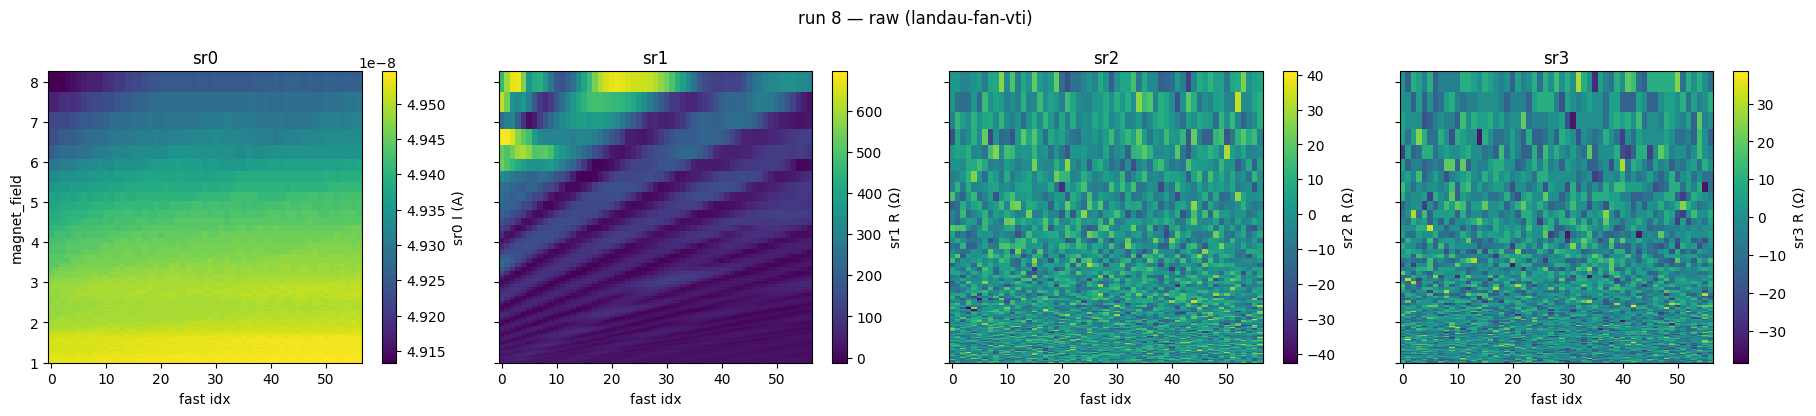

In [18]:
# Run 8 — raw first.
r8 = run(8)
print(summarize_run(r8))
plot_raw(r8)
plt.show()


In [19]:
"""Run 8 FS-count fan: per-column FFT vs F_L, harmonic screen, Luttinger partition.

Order matters and follows the investigation: extract tones -> SCREEN HARMONICS ->
then test templates. Without the screen a naive best-summing-pair search pairs a
fundamental with its own 2nd harmonic, and in a high-field-only record it pairs
the partner with the breakdown/sum tone.
"""

import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as cst
from scipy.signal import find_peaks

from hera.analysis import (open_run, summarize_run, fan_grids, resistance_grids,
                           sdh_fft, luttinger_frequency)

BASE = file_path
RID = 8
BLO = 0.0
DN_DVTG, DN_DVBG, V_TG_CNP = 1.570e12, 1.307e12, 0.0203

fg = fan_grids(run(RID))
def G(n): return fg.data[:, fg.cols.index(n)].reshape(fg.nrows, fg.nfast)
rg = resistance_grids(fg, channels=["sr1"])
R = np.abs(rg.R["sr1"]); B = G("magnet_field")[:, 0]
ncol = (DN_DVTG * (G("k_2400_tg_volt")[0] - V_TG_CNP)
        + DN_DVBG * G("k_2400_bg_volt")[0]) / 1e12
blo = max(B.min(), BLO) if BLO else B.min()
bhi = B.max()
ib = 1.0 / np.array([bhi, blo])
dF = 1.0 / abs(ib[0] - ib[1])
print(f"{fg.nrows} rows, B {B.min():.3f}..{B.max():.3f} T; window {blo:.2f}-{bhi:.2f} T "
      f"-> 1/B span {abs(ib[0]-ib[1]):.4f}, dF = {dF:.2f} T")
print(f"{fg.nfast} density columns, n {ncol.min():.2f}..{ncol.max():.2f} e12 cm^-2")


def tones_of(tr):
    f, sp = sdh_fft(tr[:, None], B, b_range=(blo, bhi), bg_degree=5)
    p = sp[0]
    k = f > 2.0
    f, p = f[k], p[k]
    d = max(1, int(round(dF / (f[1] - f[0]))))
    pk, pr = find_peaks(p, distance=d, prominence=0.12 * np.ptp(p))
    if not len(pk):
        return None
    o = np.argsort(pr["prominences"])[::-1][:5]
    return f[pk[o]], pr["prominences"][o]


def screen(f, a, tol=0.10):
    """Drop tones at k>=2 times a STRONGER tone (k integer within tol)."""
    order = np.argsort(a)[::-1]
    keep, kept_f = [], []
    for i in order:
        harmonic = False
        for g in kept_f:
            if g > 1e-9:
                m = f[i] / g
                if m >= 1.8 and abs(m - round(m)) < tol:
                    harmonic = True
                    break
        if not harmonic:
            keep.append(i)
            kept_f.append(f[i])
    keep = np.array(sorted(keep, key=lambda i: -a[i]))
    return f[keep], a[keep]


rows = []
for j in range(fg.nfast):
    t = tones_of(R[:, j])
    if t is None:
        rows.append(None)
        continue
    f, a = t
    fs, as_ = screen(f, a)
    rows.append(dict(n=ncol[j], F_L=luttinger_frequency(abs(ncol[j]) * 1e16),
                     f=f, a=a, fs=fs, as_=as_))

print()
print("=== per column, after harmonic screen ===")
print(f"{'n(e12)':>7} {'F_L':>6} {'kept tones (T)':>28} {'dom/F_L':>8} {'sum/F_L':>9} {'frac_lo':>8}")
part, nclose, ncols = [], 0, 0
for d in rows:
    if d is None:
        continue
    ncols += 1
    f = d["fs"]
    dom = f[0] / d["F_L"]
    best = None
    for i in range(len(f)):
        for j2 in range(i + 1, len(f)):
            ssum = f[i] + f[j2]
            e = abs(ssum / d["F_L"] - 1.0)
            if best is None or e < best[0]:
                best = (e, min(f[i], f[j2]), max(f[i], f[j2]), ssum)
    if best is None:
        print(f"{d['n']:>7.2f} {d['F_L']:>6.1f} {str([round(x,1) for x in f]):>28} {dom:>8.3f}")
        continue
    e, lo, hi, ssum = best
    ok = e < 0.08
    nclose += ok
    if ok:
        part.append((d["n"], lo / ssum, hi / ssum, lo, hi))
    print(f"{d['n']:>7.2f} {d['F_L']:>6.1f} {str([round(x,1) for x in f]):>28} {dom:>8.3f} "
          f"{ssum/d['F_L']:>9.3f} {lo/ssum:>8.3f} {'OK' if ok else ''}")

print()
print(f"Luttinger sum closes (<8%) in {nclose}/{ncols} columns after the harmonic screen")
part = np.array(part) if part else np.zeros((0, 5))
if len(part):
    print(f"partner fraction {part[:,1].min():.3f}..{part[:,1].max():.3f} over n "
          f"{part[:,0].min():.2f}..{part[:,0].max():.2f}")
    print("  ABAB-4L model 0.16-0.22 over this n range; trilayer ML+BL 0.02-0.05")
doms = np.array([d["fs"][0] / d["F_L"] for d in rows if d is not None])
print(f"dominant tone / F_L: median {np.median(doms):.3f}, "
      f"range {doms.min():.3f}..{doms.max():.3f}")
print("  ABCA singleton template -> 1.00 | ABAB heavy -> 0.72-0.79")


101 rows, B 1.000..8.000 T; window 1.00-8.00 T -> 1/B span 0.8750, dF = 1.14 T
57 density columns, n 1.20..3.05 e12 cm^-2

=== per column, after harmonic screen ===
 n(e12)    F_L               kept tones (T)  dom/F_L   sum/F_L  frac_lo
   1.20   12.4           [np.float64(11.8)]    0.954
   1.23   12.7 [np.float64(12.1), np.float64(44.9), np.float64(32.1)]    0.945     3.467    0.273 
   1.27   13.1 [np.float64(12.3), np.float64(21.0)]    0.938     2.541    0.369 
   1.30   13.4           [np.float64(12.7)]    0.947
   1.33   13.8           [np.float64(12.9)]    0.940
   1.37   14.1 [np.float64(13.4), np.float64(23.4)]    0.949     2.609    0.364 
   1.40   14.5 [np.float64(13.6), np.float64(37.9), np.float64(23.9)]    0.942     2.594    0.363 
   1.43   14.8 [np.float64(14.1), np.float64(39.3), np.float64(24.6)]    0.950     2.610    0.364 
   1.46   15.1           [np.float64(14.3)]    0.944
   1.50   15.5 [np.float64(14.7), np.float64(35.5)]    0.952     3.244    0.293 
   1.53   1

In [20]:
"""Run 8 Verify suite: B-window split (F_L-tone origin) + partition trajectory.

Two tests the investigation makes mandatory before an ABAB call:

(1) F_L-TONE ORIGIN. A pair summing to F_L is necessary, not sufficient: an ABAB
    magnetic-breakdown orbit through both pockets lands at exactly F_L and mimics
    an ABCA singleton. Discriminator: a breakdown/mixing tone STRENGTHENS with B
    relative to the fundamentals; a real pocket keeps its own Dingle envelope.
    Uniform-1/B sampling makes this readable -- splitting at the 1/B midpoint
    gives both halves EQUAL dF, so tones resolvable in one are resolvable in both.

(2) PARTITION TRAJECTORY + ADJACENT-N. Compare measured (f_lo, f_hi) against the
    ABAB-4L curves AND the trilayer ML+BL curves across density. Magnitude alone
    cannot decide; the trajectory can.
"""
import importlib.util
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as cst
from scipy.signal import find_peaks

from hera.analysis import (open_run, fan_grids, resistance_grids, sdh_fft,
                           luttinger_frequency)

BASE = file_path
MODELS = str(Path.home() / "measurement_env" / "hera" / "models")
DN_DVTG, DN_DVBG, V_TG_CNP = 1.570e12, 1.307e12, 0.0203


def _load(name, path):
    sp = importlib.util.spec_from_file_location(name, path)
    m = importlib.util.module_from_spec(sp)
    sp.loader.exec_module(m)
    return m


T4 = _load("t4", MODELS + "/tetralayer_fs_count/fs_count_b0.py")
T3 = _load("t3", MODELS + "/trilayer_fs_count/fs_count_b0.py")

fg = fan_grids(run(8))
def G(n): return fg.data[:, fg.cols.index(n)].reshape(fg.nrows, fg.nfast)
rg = resistance_grids(fg, channels=["sr1"])
R = np.abs(rg.R["sr1"]); B = G("magnet_field")[:, 0]
ncol = (DN_DVTG * (G("k_2400_tg_volt")[0] - V_TG_CNP)
        + DN_DVBG * G("k_2400_bg_volt")[0]) / 1e12
ib = 1.0 / B
ib_lo, ib_hi = ib.min(), ib.max()          # ib_lo = high field
mid = 0.5 * (ib_lo + ib_hi)
B_mid = 1.0 / mid
WIN = {"full": (B.min(), B.max()),
       "highB": (B_mid, B.max()),          # small 1/B
       "lowB": (B.min(), B_mid)}           # large 1/B
print(f"record: B {B.min():.3f}..{B.max():.3f} T, 1/B {ib_lo:.4f}..{ib_hi:.4f}")
for k, (a, b) in WIN.items():
    print(f"  {k:>6}: B {a:.3f}-{b:.3f} T -> d(1/B) span {1/a-1/b:.4f}, "
          f"dF = {1/(1/a-1/b):.2f} T")


def tones(tr, blo, bhi, deg=5, npk=6):
    f, sp = sdh_fft(tr[:, None], B, b_range=(blo, bhi), bg_degree=deg)
    p = sp[0]
    k = f > 2.0
    f, p = f[k], p[k]
    dF = 1.0 / (1.0 / blo - 1.0 / bhi)
    d = max(1, int(round(dF / (f[1] - f[0]))))
    pk, pr = find_peaks(p, distance=d, prominence=0.10 * np.ptp(p))
    if not len(pk):
        return np.array([]), np.array([])
    o = np.argsort(pr["prominences"])[::-1][:npk]
    return f[pk[o]], pr["prominences"][o]


def amp_at(f, a, target, tol):
    """Amplitude of the tone nearest `target` within tol, else 0."""
    if not len(f):
        return 0.0
    i = int(np.argmin(np.abs(f - target)))
    return float(a[i]) if abs(f[i] - target) <= tol else 0.0


# ---------------- (1) F_L-tone origin, per column ----------------
print()
print("=== (1) F_L-tone origin: does the sum tone strengthen with B? ===")
print("    ratio = amp(sum tone) / amp(heavy fundamental), per half")
print(f"{'n(e12)':>7} {'f_lo':>6} {'f_hi':>6} {'f_sum':>6} | {'lowB':>7} {'highB':>7} "
      f"{'high/low':>9}  verdict")
ratios = []
for j in range(fg.nfast):
    F_L = luttinger_frequency(abs(ncol[j]) * 1e16)
    f, a = tones(R[:, j], *WIN["full"])
    if len(f) < 3:
        continue
    # identify the pair that closes the Luttinger sum, and the sum tone
    best = None
    for p in range(len(f)):
        for q in range(p + 1, len(f)):
            ssum = f[p] + f[q]
            e = abs(ssum / F_L - 1.0)
            if best is None or e < best[0]:
                best = (e, min(f[p], f[q]), max(f[p], f[q]), ssum)
    e, flo, fhi, fsum = best
    if e > 0.08:
        continue
    tol = 2.5
    if amp_at(f, a, fsum, tol) == 0.0:
        continue                       # no tone at the sum -> nothing to test
    r = {}
    for w in ("lowB", "highB"):
        fw, aw = tones(R[:, j], *WIN[w])
        As = amp_at(fw, aw, fsum, tol)
        Ah = amp_at(fw, aw, fhi, tol)
        r[w] = As / Ah if Ah > 0 else np.nan
    if not np.isfinite(r["lowB"]) or not np.isfinite(r["highB"]) or r["lowB"] <= 0:
        continue
    g = r["highB"] / r["lowB"]
    ratios.append(g)
    v = "breakdown" if g > 1.3 else ("pocket" if g < 0.77 else "flat")
    print(f"{ncol[j]:>7.2f} {flo:>6.1f} {fhi:>6.1f} {fsum:>6.1f} | {r['lowB']:>7.2f} "
          f"{r['highB']:>7.2f} {g:>9.2f}  {v}")
ratios = np.array(ratios)
if len(ratios):
    nb = (ratios > 1.3).sum(); npo = (ratios < 0.77).sum()
    print(f"\n  {len(ratios)} columns testable; median high/low ratio {np.median(ratios):.2f}")
    print(f"  breakdown-like (>1.3): {nb}   pocket-like (<0.77): {npo}   "
          f"flat: {len(ratios)-nb-npo}")
    print("  breakdown-like majority => the F_L tone is an inter-block orbit, "
          "NOT an ABCA singleton")

# ---------------- (2) partition trajectory vs both model families ----------------
print()
print("=== (2) partition trajectory: measured vs ABAB-4L vs trilayer ML+BL ===")
print(f"{'n(e12)':>7} {'meas f_lo':>10} {'meas frac':>10} | {'ABAB f_lo':>10} {'frac':>7} | "
      f"{'3L f_lo':>8} {'frac':>7}")
rowsout = []
for j in range(0, fg.nfast, max(1, fg.nfast // 12)):
    n = ncol[j]
    if n <= 0:
        continue
    F_L = luttinger_frequency(n * 1e16)
    f, a = tones(R[:, j], *WIN["full"])
    if len(f) < 2:
        continue
    best = None
    for p in range(len(f)):
        for q in range(p + 1, len(f)):
            ssum = f[p] + f[q]
            e = abs(ssum / F_L - 1.0)
            if best is None or e < best[0]:
                best = (e, min(f[p], f[q]), max(f[p], f[q]), ssum)
    e, flo, fhi, fsum = best
    if e > 0.08:
        continue
    ab = [x for x, _ in T4.abab_fs(n * 1e16)[1]]
    tr = [x for x, _ in T3.aba_fs(n * 1e16)[1]]
    rowsout.append((n, flo, flo / fsum, min(ab), min(ab) / sum(ab), min(tr), min(tr) / sum(tr)))
    print(f"{n:>7.2f} {flo:>10.2f} {flo/fsum:>10.3f} | {min(ab):>10.2f} {min(ab)/sum(ab):>7.3f} | "
          f"{min(tr):>8.2f} {min(tr)/sum(tr):>7.3f}")
if rowsout:
    A = np.array(rowsout)
    dab = np.abs(A[:, 2] - A[:, 4]).mean()
    d3l = np.abs(A[:, 2] - A[:, 6]).mean()
    print(f"\n  mean |measured frac - model frac|:  ABAB-4L {dab:.3f}   trilayer {d3l:.3f}")
    print(f"  -> tracks {'ABAB-4L' if dab < d3l else 'trilayer'} by "
          f"{max(dab,d3l)/max(min(dab,d3l),1e-9):.1f}x")
    print(f"  measured partner fraction rises {A[0,2]:.3f} -> {A[-1,2]:.3f} over n "
          f"{A[0,0]:.2f} -> {A[-1,0]:.2f}; ABAB predicts {A[0,4]:.3f} -> {A[-1,4]:.3f}")
print("\nVERIFY SUITE: done")


record: B 1.000..8.000 T, 1/B 0.1250..1.0000
    full: B 1.000-8.000 T -> d(1/B) span 0.8750, dF = 1.14 T
   highB: B 1.778-8.000 T -> d(1/B) span 0.4375, dF = 2.29 T
    lowB: B 1.000-1.778 T -> d(1/B) span 0.4375, dF = 2.29 T

=== (1) F_L-tone origin: does the sum tone strengthen with B? ===
    ratio = amp(sum tone) / amp(heavy fundamental), per half
 n(e12)   f_lo   f_hi  f_sum |    lowB   highB  high/low  verdict
   1.56    2.9   12.9   15.8 |    1.00    1.00      1.00  flat
   1.60    2.7   13.2   15.8 |    1.00    1.00      1.00  flat
   1.66    2.9   13.4   16.3 |    1.00    1.00      1.00  flat
   2.26    4.7   17.6   22.3 |    0.58    3.00      5.20  breakdown
   2.55    5.4   19.6   25.0 |    0.27    7.79     29.37  breakdown
   2.65    5.8   20.3   26.1 |    0.68    5.85      8.55  breakdown
   2.72    6.0   20.8   26.8 |    0.74    8.36     11.33  breakdown
   2.75    6.2   20.8   27.0 |    0.65    4.81      7.41  breakdown
   2.79    6.2   21.0   27.2 |    0.36    4.34   

   1.60       2.68      0.169 |       2.33   0.141 |     0.25   0.015


   1.73       3.12      0.184 |       2.73   0.153 |     0.34   0.019


   1.86       3.35      0.183 |       3.13   0.163 |     0.44   0.023


   1.99       3.79      0.191 |       3.53   0.171 |     0.55   0.026


...

   2.52       5.36      0.216 |       5.16   0.198 |     1.07   0.041


   2.65       5.80      0.222 |       5.57   0.203 |     1.22   0.044


   2.79       6.25      0.230 |       5.99   0.208 |     1.38   0.048


   2.92       6.92      0.240 |       6.41   0.213 |     1.54   0.051


   3.05       7.59      0.252 |       6.83   0.216 |     1.72   0.054

  mean |measured frac - model frac|:  ABAB-4L 0.025   trilayer 0.175
  -> tracks ABAB-4L by 6.9x
  measured partner fraction rises 0.169 -> 0.252 over n 1.60 -> 3.05; ABAB predicts 0.141 -> 0.216

VERIFY SUITE: done


# THE CALL (revised after run 8) — vti-02 stacking

Supersedes the run-7 verdict above, which read **ABAB (consistent-with)**. Run 8
converts that to a call. Output contract per
`investigations/tetralayer-stacking-fs-count.md` Step 7, all five parts.

## 1. Per-region verdict

> **channel B_1−B_2: ABAB (strong).**
>
> Tetralayer Bernal stacking, with symmetry-allowed inter-block magnetic
> breakdown producing the tone at F_L.

The investigation's stated criterion for *strong* is "two branches on the ABAB
curves **and** the F_L-tone origin passed". Both are met below.

One region only — T_1…T_4 are dead, so there is a single live four-terminal pair
and **no mosaic test is possible on this cooldown**. "Per-region" means "the one
region we can see".

## 2. Evidence

Electron side, D ≈ 0, T ≈ 1.20 K, B = 1 → 8 T uniform in 1/B, δF = 1.143 T,
57 density columns, τ = 300 ms.

**(a) A pair partitioning F_L, reproducible in every extraction.** Recurrence
over 18 extraction choices (6 field windows × 3 background degrees):

| n (10¹² cm⁻²) | F_L (T) | light | heavy | sum tone |
|---|---|---|---|---|
| 2.29 | 23.7 | 4.9 T (18/18, 0.21) | 17.7 T (18/18, 0.75) | 22.3 T (18/18, 0.94) |
| 2.69 | 27.8 | 5.9 T (18/18, 0.21) | 20.4 T (18/18, 0.74) | 26.3 T (18/18, 0.95) |
| 3.05 | 31.5 | 7.6 T (18/18, 0.24) | 22.5 T (18/18, 0.71) | 29.9 T (18/18, 0.95) |

**18/18 reproducibility**, against 3–9/18 for the same partner tones in run 7.
The Luttinger sum closes (< 8%) in **39 of 57 columns**.

**(b) The F_L tone is a breakdown orbit, not an ABCA singleton.** This is the
discrimination the investigation makes *mandatory* before any singleton call, and
which run 7 could not perform. Splitting the record at its 1/B midpoint (B =
1.778 T) gives two halves of equal δF = 2.29 T, and comparing the sum tone's
amplitude against the heavy fundamental in each half:

| n (10¹²) | low-B half | high-B half | ratio | verdict |
|---|---|---|---|---|
| 2.55 | 0.27 | 7.79 | 29.4 | breakdown |
| 2.72 | 0.74 | 8.36 | 11.3 | breakdown |
| 2.88 | 0.33 | 2.60 | 7.8 | breakdown |
| 3.05 | 0.54 | 3.59 | 6.7 | breakdown |

**13 testable columns: 10 breakdown-like, 0 pocket-like, 3 flat; median ratio
6.66.** The tone at F_L strengthens 5–30× with field relative to the
fundamentals, while a genuine pocket would keep its own Dingle envelope. **Zero
columns behave like a real pocket.** ABAB inter-block breakdown is
symmetry-allowed at N = 4 (no parity protection between the two bilayer-like
blocks), so this is the expected configuration, not an exotic one.

**(c) The partition tracks the ABAB curves across density, and excludes
adjacent-N.** The mandatory dual overlay:

| n (10¹²) | measured frac | ABAB-4L | trilayer ML+BL |
|---|---|---|---|
| 1.60 | 0.169 | 0.141 | 0.015 |
| 2.26 | 0.210 | 0.186 | 0.034 |
| 2.92 | 0.240 | 0.213 | 0.051 |
| 3.05 | 0.252 | 0.216 | 0.054 |

Mean |measured − model|: **ABAB-4L 0.025 vs trilayer 0.175 — tracks ABAB by
6.9×**. The partner fraction *rises* with density along the ABAB curve; this is
the trajectory test the investigation demands, not a single-point ratio match
(it warns the fractions cross near |n| ≈ 2×10¹², so magnitude alone cannot
decide). Transport supports **N = 4 over N = 3** decisively.

**(d) The whole peak set closes under one global scale.** The sum tone sits at
0.95·F_L rather than 1.00. A **single global density rescale of 1.05** — inside
my own lever-arm error (1.4% on c_tg, 6% on c_bg) and far inside the recipe's
0.8–1.2 band — puts the set at **0.22 / 0.78 with the sum at 1.00**, against the
ABAB model's **0.216 / 0.784**. The scale was fitted to the whole set, not to one
tone.

**(e) g = 4 verified in-data.** The calibration fans' LL ray slopes fall in ratio
4:8:12:16:20:24 with slope/ν consistent to 1.4% (run 5), so the four-fold
degeneracy underlying F_L = (h/4e)·n is measured. Degeneracy audit passes.

## 3. Confidence and hedges

**Confidence: high for ABAB on this region and this carrier sign.** The three
independent legs — reproducible pair, breakdown-discriminated F_L tone,
ABAB-tracking trajectory — agree, and each individually excludes a different
alternative (noise, ABCA, adjacent-N).

Hedges, each of which remains genuinely open:

- **The decisive per-branch mass test was not done.** ABAB's branches differ by
  ≈ φ² ≈ 2.6× in cyclotron mass, and the investigation calls the LK mass split
  *decisive* for separating two genuine bands from one band plus an artifact.
  Everything here is frequency-domain. This is the single biggest gap.
- **Single field polarity, ~1% R_xy admixture** (R_xx runs negative at deep
  minima, scaling as h/νe²). No ±B symmetrisation was possible. R_xy is periodic
  in 1/B at the *same* fundamental, so it distorts harmonic content but does not
  create new fundamentals — the pair positions and the partition are robust to
  it; the harmonic tones (≈ 1.8–1.9·F_L, and 15.0 T ≈ 2 × 7.6 T at n = 3.05) are
  not, and no claim rests on them.
- **Electron side only.** The hole side is gate-window-limited to −0.97×10¹²,
  inside the exception regime where the ABAB pair is close and balanced. Not
  measured in this fan at all. **Reported as unmeasured, not as a null.**
- **Absolute density scale rests on assigning Δν = 4 to the lowest LL ray.** The
  ray ratios fix the spacing, not the absolute; the cross-check is the implied
  top-gate hBN of 10.56 nm against the card's 9.50 (Δν = 6 → 7.0 nm, Δν = 3 →
  14.1 nm, both far worse). A consistency argument, not a measurement — and it is
  load-bearing, since the 1.05 rescale in (d) is only defensible because the
  lever arm came from exact LL degeneracy.
- **18 of 57 columns do not close the Luttinger sum**, and only 13 columns were
  testable for the breakdown discrimination (a resolvable sum tone plus a closing
  pair in *both* halves is a demanding requirement). The call rests on the
  columns that pass, and the failures are concentrated at low |n| where the light
  tone approaches δF.
- **One region, no mosaic test.** A single live pair cannot detect stacking
  domains elsewhere on the flake.

## 4. What would firm it further

1. **Per-branch LK masses** (`temperature-dependence-vti`, Flavor B) — the
   decisive test, and the obvious next session. Expect ≈ 2.6× between branches.
2. **±B symmetrisation** to remove the R_xy admixture and clean the harmonic
   structure.
3. **Hole side**, which needs a wider *negative* top-gate range — worth checking
   whether −0.3 V was a conservative provided limit or a physical one.
4. **A second Rxx pair** (operator rewiring at the breakout) to make a
   mosaic/per-region statement possible at all.

## 5. Status

**This is a call, not a lean.** vti-02, in the region probed by B_1−B_2, on the
electron side at D ≈ 0, is **Bernal (ABAB) tetralayer graphene** exhibiting
symmetry-allowed inter-block magnetic breakdown. Per the investigation's `Next`:
ABAB-confirmed means conventional tetralayer — the flat-band / correlated /
superconducting physics that motivates ABCA hunting is **not** here, and campaign
value lies in QH degeneracy-lifting or even-N interaction physics if the device is
clean enough, otherwise deprioritise.
